## Table Of Contents:
<a class="anchor" id="Top"></a>
* [Importing all the required Libraries](#first-bullet)
* [Data Insertion and Understanding of Data](#second-bullet)
* [Handling Missing Data](#third-bullet)
* [Descriptive Statistics](#fourth-bullet)
* [Exploratory Data Analysis](#fifth-bullet)
* [Version - 1](#sixth-bullet)
* [Version - 2](#seventh-bullet)
* [Data Resampling](#eighth-bullet)
* [Feature Selection](#ninth-bullet)
* [Test - Train Split](#tenth-bullet)
* [Logistic Regression](#eleventh-bullet)
* [Neural Networks](#12-bullet)
* [Random Forest Classifier](#13-bullet)
* [KNN Classifier](#14-bullet)
* [Gradient Boosting Classifier](#15-bullet)
* [Support Vector Classifier](#16-bullet)
* [Decision Tree Classifier](#17-bullet)
* [ROC Curves](#18-bullet)
* [Feature Importance using LIME](#19-bullet)
* [Disease Prevention Using Web Crawling](#20-bullet)

## <a class="anchor" id="first-bullet"></a> Importing all required libraries
*[Back to Top](#Top)

In [188]:
import pandas as pd
import numpy as np
from matplotlib import pyplot
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
import matplotlib
%matplotlib inline
import seaborn as sns
color = sns.color_palette()
from IPython.display import display
pd.options.display.max_columns = None
import keras
import pickle
import re
import spacy
from spacy import displacy
from spacy.matcher import Matcher 
from spacy.tokens import Span 

import networkx as nx
from tqdm import tqdm
# Common sklearn Model Helpers
from sklearn import feature_selection
from sklearn import model_selection
from sklearn import metrics
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# sklearn modules for performance metrics
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve
from sklearn.metrics import auc, roc_auc_score, roc_curve, recall_score, log_loss
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, make_scorer
from sklearn.metrics import average_precision_score



from sklearn.model_selection import train_test_split  # import 'train_test_split'
from sklearn.metrics import confusion_matrix, average_precision_score, classification_report
from sklearn.model_selection import cross_val_predict, train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
import xgboost as xgb
from collections import Counter

from sklearn.preprocessing import RobustScaler, MinMaxScaler
import os
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import chi2
from sklearn.feature_selection import SelectKBest

## <a class="anchor" id="second-bullet"></a> Data Insertion & Understanding
*[Back to Top](#Top)

In [189]:
data_frame = pd.read_csv("C:/Users/16674/Desktop/UMBC-MS_CS/First_Sem/Introduction to Machine Learning/Project/framingham.csv")

In [190]:
data_frame.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [191]:
#Shape of dataset

print ('No. of Records :', data_frame.shape[0], '\nNo. of Features : ', data_frame.shape[1])

No. of Records : 4240 
No. of Features :  16


In [192]:
#Let us check datset's attribute info

data_frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


In [193]:
data_frame.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


Observations :

1. Some the features are Discrete so let us analyze continuous ones
2. Age : We can see that Min. age of subject found in given records is 32 while Max. being 70. So our values are ranging from 32 to 70.
3. cigsPerDay : Subject smoking Cig. per day is as low as nill while we have 70 Cigs. per day making the Peak.
4. totChol : Min. Cholesterol level recorded in our dataset is 107 while Max. is 696.
5. sysBP : Min. Systolic Blood Pressure observed in Subject is 83 while Max. is 295.
6. diaBP : Min. Diastolic Blood Pressure observed in Subject is 48 while Max. is 142.
7. BMI : Body Mass Index in our dataset ranges from 15.54 to 56.
8. heartRate : Observed Heartrate in our case study is 44 to 143.
9. glucose : Glucose sugar level range is 40 to 394.

In [194]:
#Examining Null values in each feature

data_frame.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

## <a class="anchor" id="third-bullet"></a>  Handle missing data from the dataset by using median
*[Back to Top](#Top)

In [195]:
#User defined function for missing value imputation

def impute_median(data):
    return data.fillna(data.median())

In [196]:
#median imputation

data_frame.glucose = data_frame['glucose'].transform(impute_median)
data_frame.education = data_frame['education'].transform(impute_median)
data_frame.heartRate = data_frame['heartRate'].transform(impute_median)
data_frame.totChol = data_frame['totChol'].transform(impute_median)
data_frame.BPMeds = data_frame['BPMeds'].transform(impute_median)

## group by classes that are in relation with other classes

by_currentSmoker = data_frame.groupby(['currentSmoker'])
data_frame.cigsPerDay = by_currentSmoker['cigsPerDay'].transform(impute_median)

by_age = data_frame.groupby(['male','age'])
data_frame.BMI = by_age['BMI'].transform(impute_median)

In [197]:
data_frame = data_frame.dropna(how = 'any', axis = 0)
print(data_frame.shape)
data_frame.head()

(4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [198]:
#Rechecking if we have any missing value left

data_frame.isnull().sum()

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64

In [199]:
#Shape of dataset

print ('No. of Records :', data_frame.shape[0], '\nNo. of Features : ', data_frame.shape[1])

No. of Records : 4240 
No. of Features :  16


## <a class="anchor" id="fourth-bullet"></a> Descriptive Statistics
*[Back to Top](#Top)

In [200]:
print('Gender')
print(data_frame['male'].value_counts(normalize = True))
print('----')
print('\n')

print('Education')
print(data_frame['education'].value_counts(normalize = True))
print('----')
print('\n')

print('BP Medication')
print(data_frame['BPMeds'].value_counts(normalize = True))
print('----')
print('\n')

print('Stroke')
print(data_frame['prevalentStroke'].value_counts(normalize = True))
print('----')
print('\n')

print('Hypertension')
print(data_frame['prevalentHyp'].value_counts(normalize = True))
print('----')
print('\n')

print('Diabetes')
print(data_frame['diabetes'].value_counts(normalize = True))
print('----')
print('\n')

Gender
0    0.570755
1    0.429245
Name: male, dtype: float64
----


Education
1.0    0.405660
2.0    0.320283
3.0    0.162500
4.0    0.111557
Name: education, dtype: float64
----


BP Medication
0.0    0.970755
1.0    0.029245
Name: BPMeds, dtype: float64
----


Stroke
0    0.994104
1    0.005896
Name: prevalentStroke, dtype: float64
----


Hypertension
0    0.689387
1    0.310613
Name: prevalentHyp, dtype: float64
----


Diabetes
0    0.974292
1    0.025708
Name: diabetes, dtype: float64
----




## Conclusion drawn from above operation-
1. Assuming that 0 is female and 1 is male - 57% is Female, 42% is Male
2. Most of the patients in the database (60%+) is below education level 2 and lower
3. 97% of the patients are not on BP Medication
4. 99% have not had a Stroke before
5. About 69% are not Hypertension patients and 31% are
6. 97% users are not diabetic

In [201]:
disease = data_frame.groupby('TenYearCHD')

print('Gender')
print(disease['male'].value_counts(normalize = True))
print('----')
print('\n')

print('Education')
print(disease['education'].value_counts(normalize = True))
print('----')
print('\n')

print('BP Medication')
print(disease['BPMeds'].value_counts(normalize = True))
print('----')
print('\n')

print('Stroke')
print(disease['prevalentStroke'].value_counts(normalize = True))
print('----')
print('\n')

print('Hypertension')
print(disease['prevalentHyp'].value_counts(normalize = True))
print('----')
print('\n')

print('Diabetes')
print(disease['diabetes'].value_counts(normalize = True))
print('----')
print('\n')

Gender
TenYearCHD  male
0           0       0.589266
            1       0.410734
1           1       0.532609
            0       0.467391
Name: male, dtype: float64
----


Education
TenYearCHD  education
0           1.0          0.388487
            2.0          0.332314
            3.0          0.167130
            4.0          0.112069
1           1.0          0.501553
            2.0          0.253106
            3.0          0.136646
            4.0          0.108696
Name: education, dtype: float64
----


BP Medication
TenYearCHD  BPMeds
0           0.0       0.976919
            1.0       0.023081
1           0.0       0.936335
            1.0       0.063665
Name: BPMeds, dtype: float64
----


Stroke
TenYearCHD  prevalentStroke
0           0                  0.996107
            1                  0.003893
1           0                  0.982919
            1                  0.017081
Name: prevalentStroke, dtype: float64
----


Hypertension
TenYearCHD  prevalentHyp
0           

## Conclusion-
1. Males seem to be slightly susceptible to Heart Disease compared to Females. (Basicaly Gender may play a role)
2. While it looks like lower education level patients are more susceptible, the overall number of lower education level patients are also much higher
3. BP Medication, Stroke and Diabetes dont seem to have too much of an impact
4. Hypertension, however, seems like it has an impact.

In [202]:
data_frame['totChol'].max()

696.0

In [203]:
data_frame['sysBP'].max()


295.0

In [204]:
data_frame = data_frame[data_frame['totChol']<600.0]
data_frame = data_frame[data_frame['sysBP']<295.0]
data_frame.shape

(4237, 16)

##  <a class="anchor" id="fifth-bullet"></a> Exploratory Data Analysis
*[Back to Top](#Top)

<AxesSubplot: >

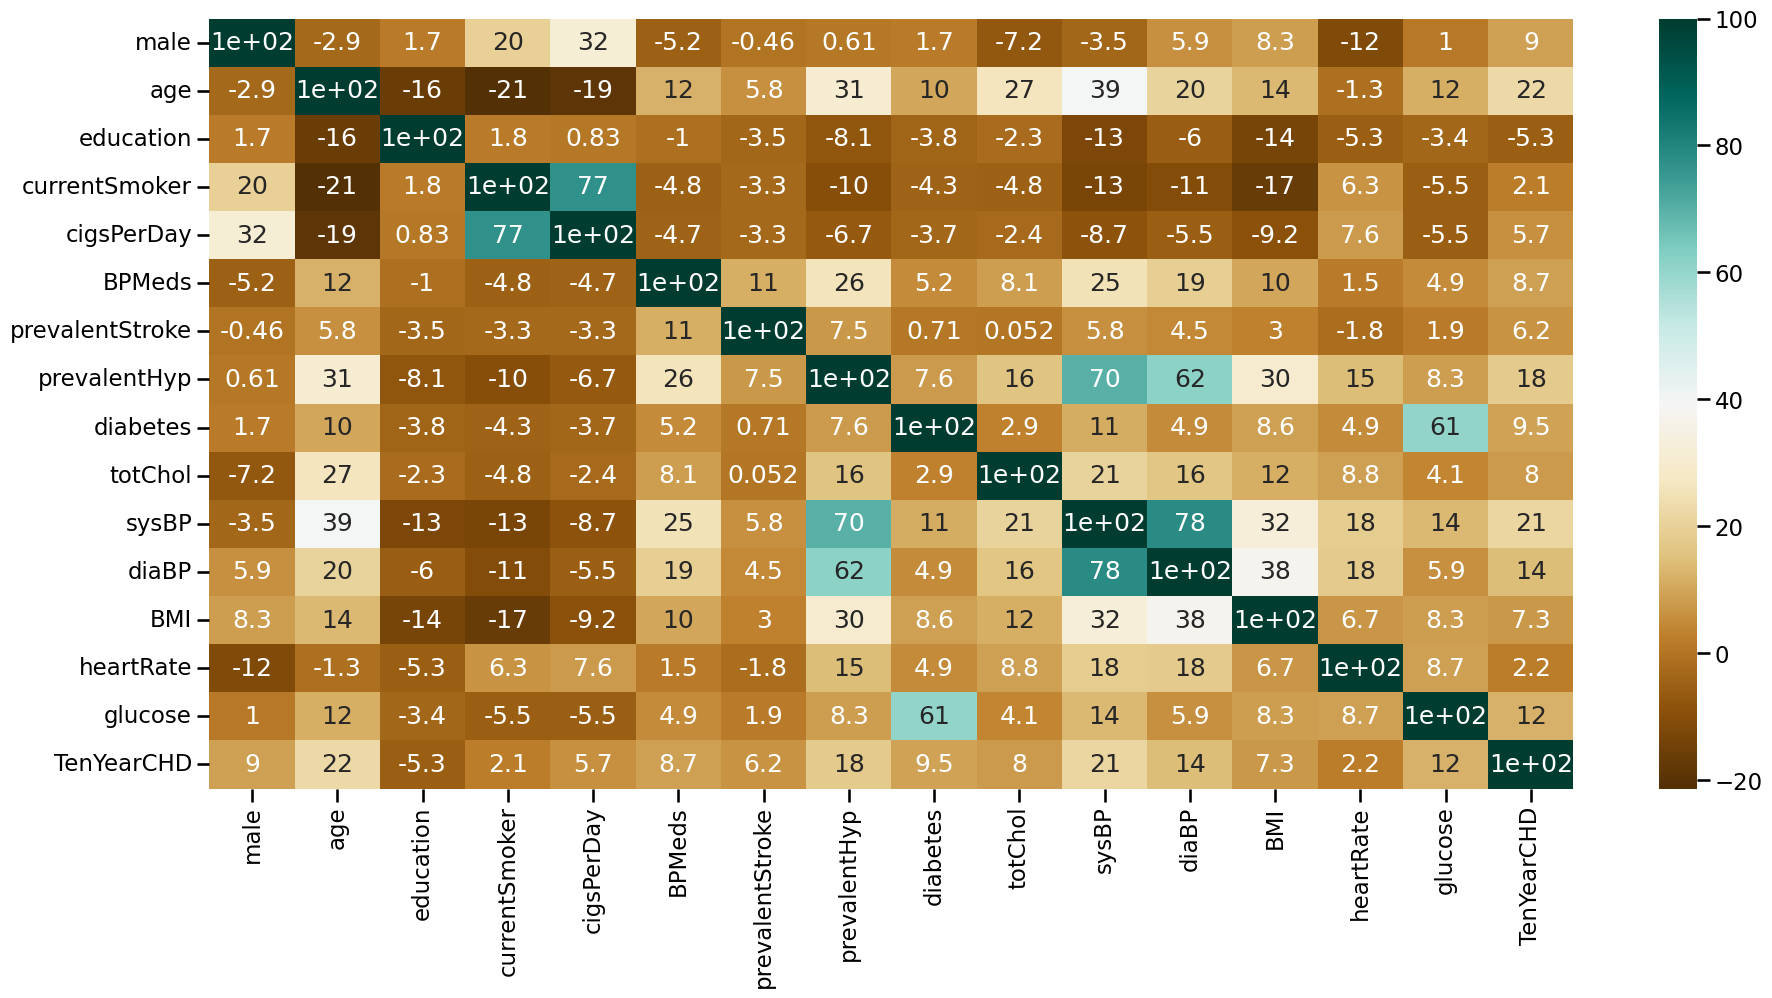

In [205]:
sns.set_context('talk')
plt.figure(figsize=(22,10))
sns.heatmap(data_frame.corr()*100, annot=True, cmap='BrBG')

There seems to be a decently strong correlation between sysBP and diaBP as well as there is negative corelation between education and output variable. Hence we will remove this column later

In [206]:
categorical_features = ['male','currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']
for feature in categorical_features:
    print(feature,':')
    print(data_frame[feature].value_counts())
    print("-----------------")

male :
0    2418
1    1819
Name: male, dtype: int64
-----------------
currentSmoker :
0    2143
1    2094
Name: currentSmoker, dtype: int64
-----------------
BPMeds :
0.0    4113
1.0     124
Name: BPMeds, dtype: int64
-----------------
prevalentStroke :
0    4212
1      25
Name: prevalentStroke, dtype: int64
-----------------
prevalentHyp :
0    2923
1    1314
Name: prevalentHyp, dtype: int64
-----------------
diabetes :
0    4129
1     108
Name: diabetes, dtype: int64
-----------------


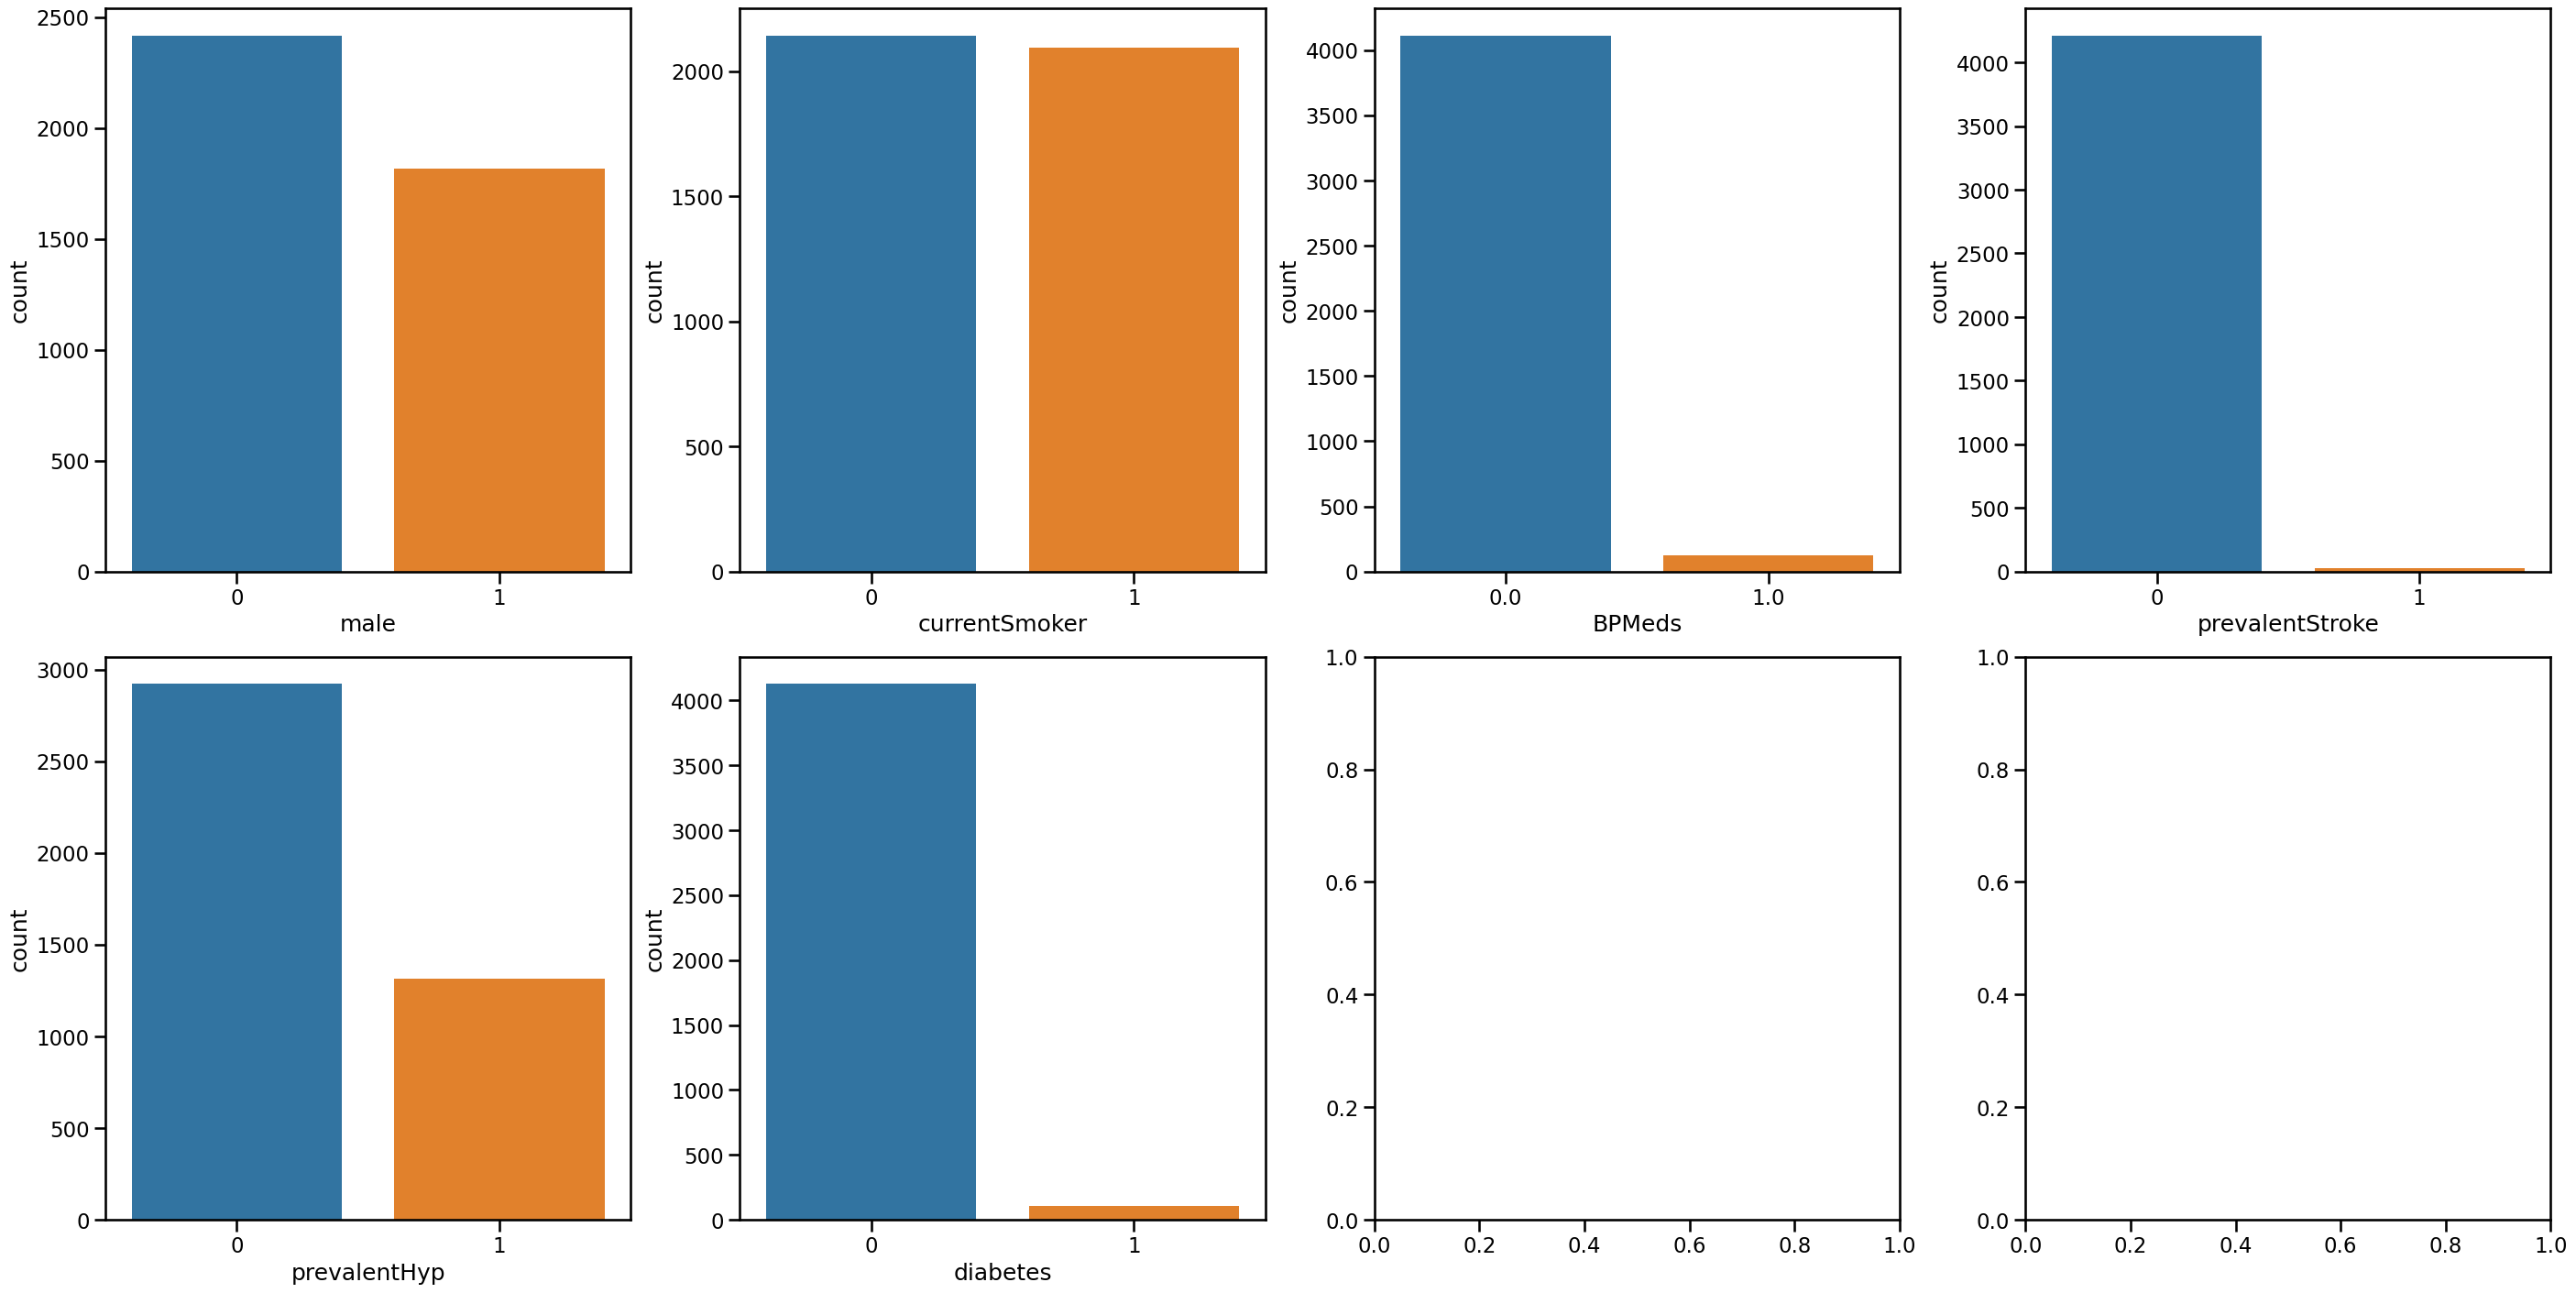

In [207]:
num_plots = len(categorical_features)
total_cols = 4
total_rows = num_plots//total_cols + 1
fig, axs = plt.subplots(nrows=total_rows, ncols=total_cols,
                        figsize=(7*total_cols, 7*total_rows), facecolor='w', constrained_layout=True)
for i, var in enumerate(categorical_features):
    row = i//total_cols
    pos = i % total_cols
    plot = sns.countplot(x=var, data=data_frame, ax=axs[row][pos])

## Among the categorical features:

BPmeds, prevalentStroke and diabetes are highly imbalanced.
There are four levels of education whereas the rest categorical features are all binary
The number of Smokers and non-Smokers in currentSmoker is almost the same

Text(0.5, 1.0, 'CHD by Gender')

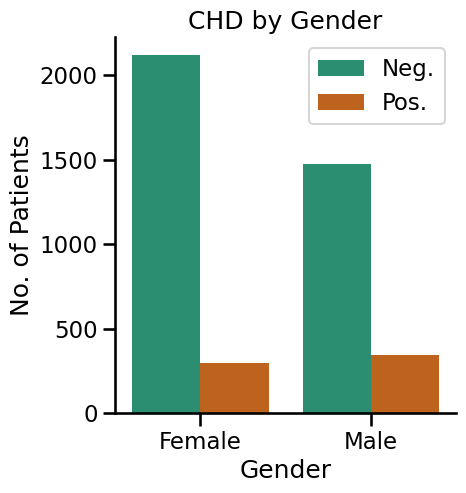

In [208]:
#CHD by Gender Viz.
sns.catplot(x='male', hue='TenYearCHD', data=data_frame, kind='count', palette='Dark2', legend=False)
plt.xlabel('Gender')
plt.xticks(ticks=[0,1], labels=['Female', 'Male'])
plt.ylabel('No. of Patients')
plt.legend(['Neg.', 'Pos.'])
plt.title('CHD by Gender')

Observations :

1. Above Bivariate Analysis plot depicts Gender wise absence / presence of Chronic Heart Disease (CHD).
2. Observations tells us that we've Excessive number of people who are not suffering from CHD.
3. Negative : Approx. 80 to 90% of Females are falling in Negative Category while Approx. 60 to 70% of Males are in Negative Slot.
4. Positive : While Approx. 10% of Females & Males are suffering from CHD.
5. By this we can say that our Dataset is Imbalanced where Approx. 80 to 90% are Negative Classifications and Approx. 10 to 15% are Positive Classes.

C:\Users\16674\AppData\Local\Temp\ipykernel_23648\1772763241.py:4: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  data_frame.hist(ax = ax)


array([[<AxesSubplot: title={'center': 'male'}>,
        <AxesSubplot: title={'center': 'age'}>,
        <AxesSubplot: title={'center': 'education'}>,
        <AxesSubplot: title={'center': 'currentSmoker'}>],
       [<AxesSubplot: title={'center': 'cigsPerDay'}>,
        <AxesSubplot: title={'center': 'BPMeds'}>,
        <AxesSubplot: title={'center': 'prevalentStroke'}>,
        <AxesSubplot: title={'center': 'prevalentHyp'}>],
       [<AxesSubplot: title={'center': 'diabetes'}>,
        <AxesSubplot: title={'center': 'totChol'}>,
        <AxesSubplot: title={'center': 'sysBP'}>,
        <AxesSubplot: title={'center': 'diaBP'}>],
       [<AxesSubplot: title={'center': 'BMI'}>,
        <AxesSubplot: title={'center': 'heartRate'}>,
        <AxesSubplot: title={'center': 'glucose'}>,
        <AxesSubplot: title={'center': 'TenYearCHD'}>]], dtype=object)

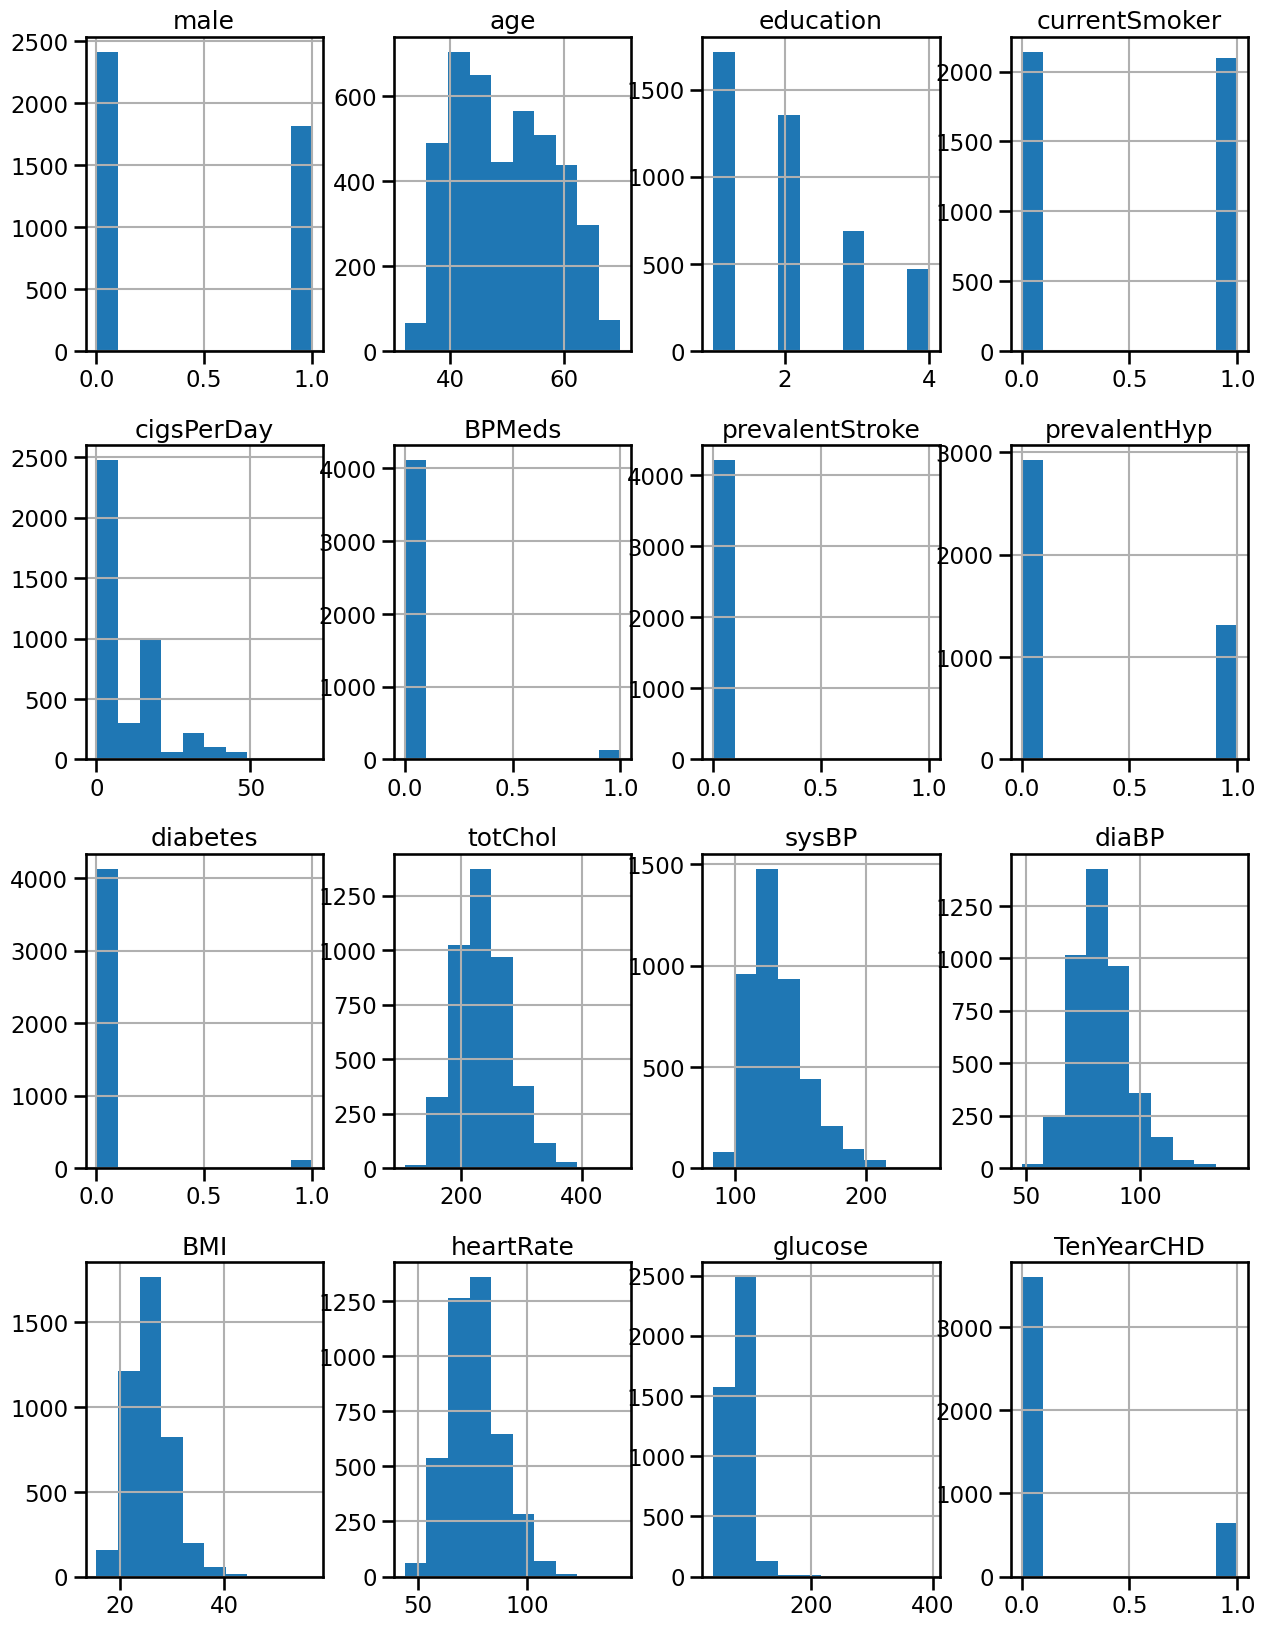

In [209]:
# checking distributions using histograms
fig = plt.figure(figsize = (15,20))
ax = fig.gca()
data_frame.hist(ax = ax)

C:\Users\16674\AppData\Local\Temp\ipykernel_23648\4017401489.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_frame['glucose'] , color='orange')
C:\Users\16674\AppData\Local\Temp\ipykernel_23648\4017401489.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_frame['totChol'], color=

Text(0.5, 1.0, 'Distribution of HeartRate')

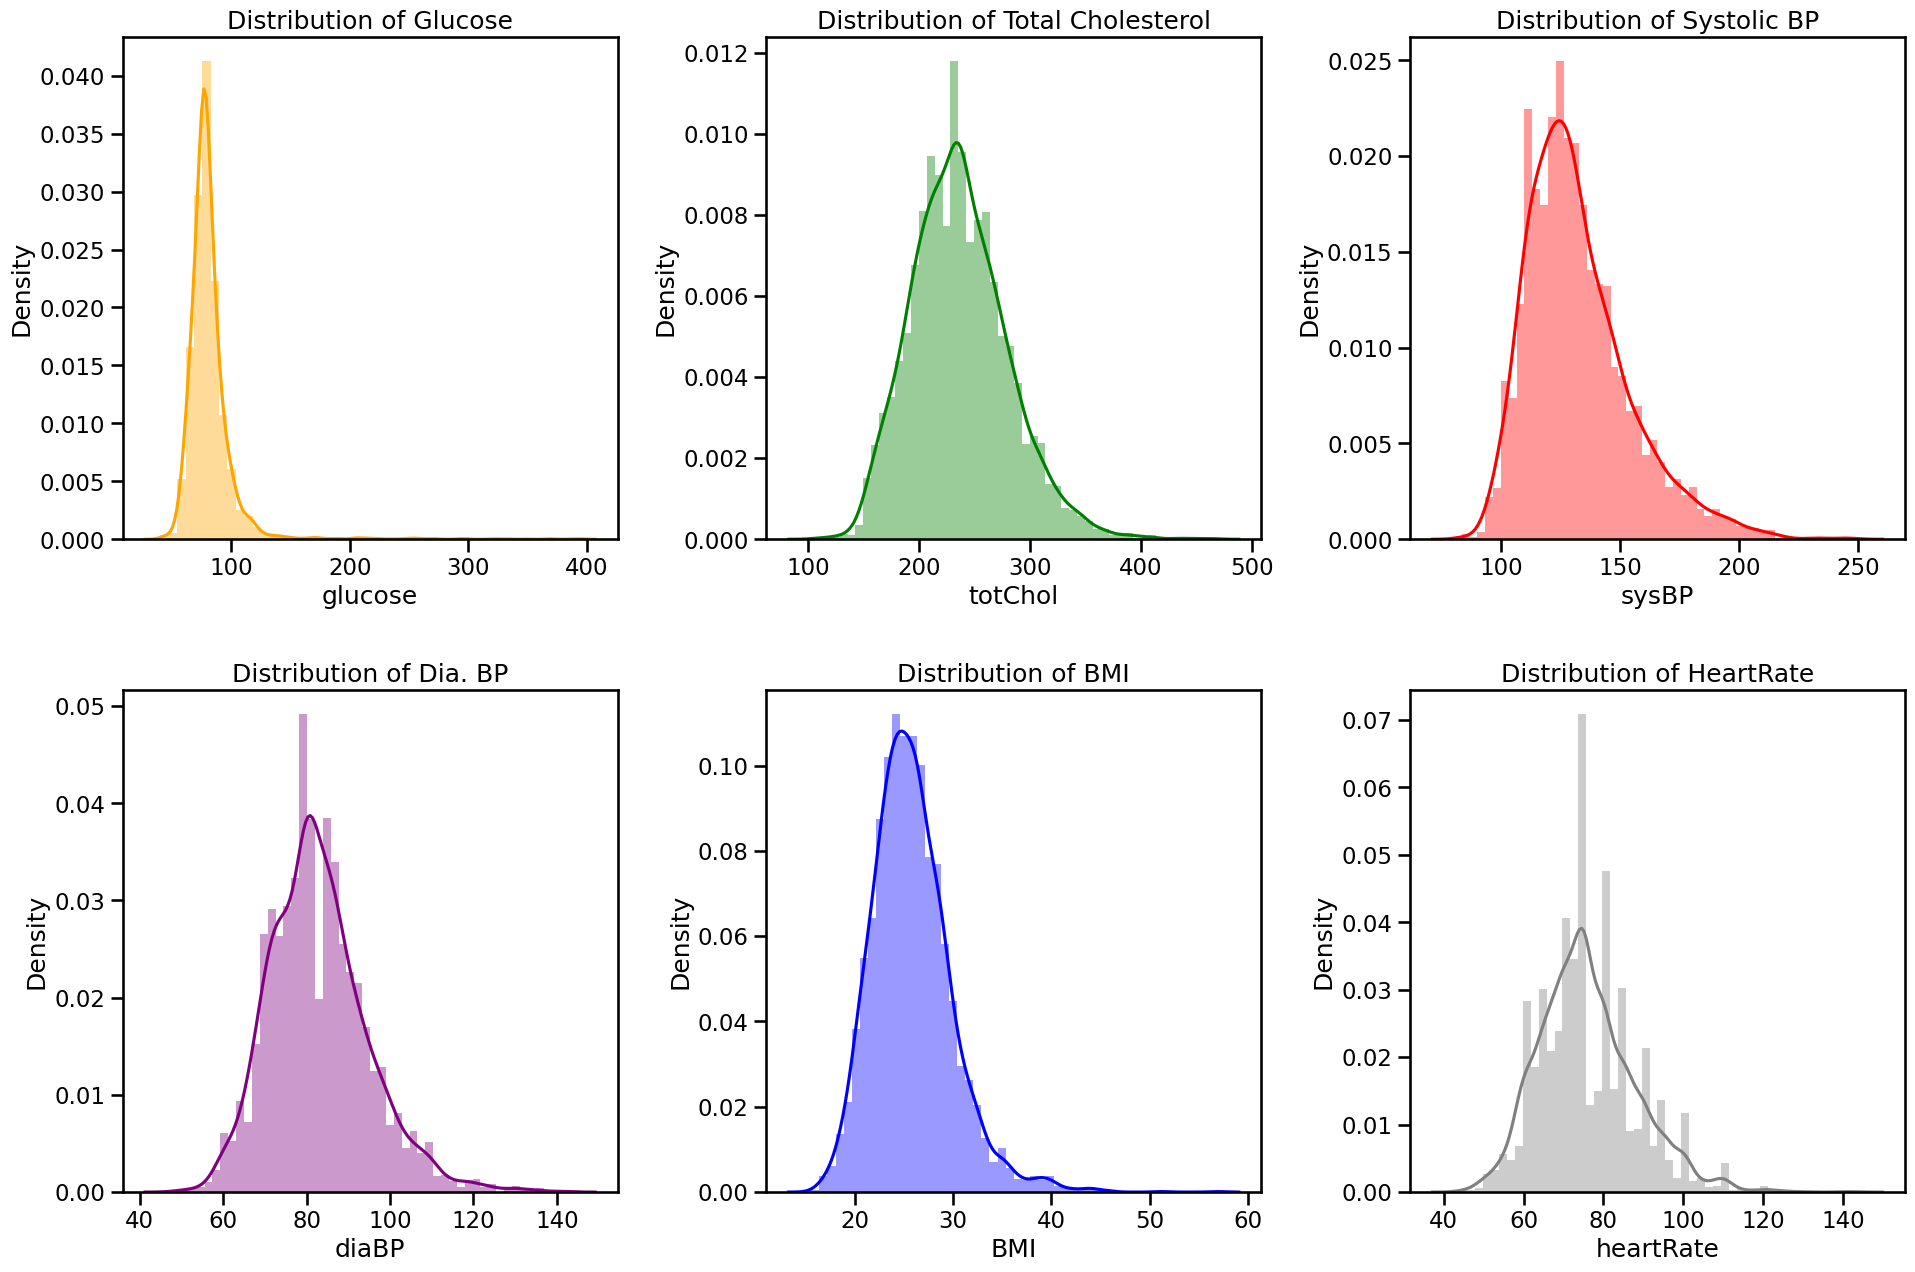

In [210]:
#Distribution of Continuous variables

plt.figure(figsize=(23,15))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

plt.subplot(2, 3, 1)
sns.distplot(data_frame['glucose'] , color='orange')
plt.title('Distribution of Glucose')

plt.subplot(2, 3, 2)
sns.distplot(data_frame['totChol'], color='g')
plt.title('Distribution of Total Cholesterol')

plt.subplot(2, 3, 3)
sns.distplot(data_frame['sysBP'], color='r')
plt.title('Distribution of Systolic BP')

plt.subplot(2, 3, 4)
sns.distplot(data_frame['diaBP'] , color='purple')
plt.title('Distribution of Dia. BP')

plt.subplot(2, 3, 5)
sns.distplot(data_frame['BMI'], color='blue')
plt.title('Distribution of BMI')

plt.subplot(2, 3, 6)
sns.distplot(data_frame['heartRate'], color='grey')
plt.title('Distribution of HeartRate')

Observations :

1. We can see Glucose, Total Cholesterol, Systolic BP & BMI is Right Skewed.
2. While Diastolic BP & Heart Rate are close to Normal / Gaussian Distribution

C:\Users\16674\AppData\Local\Temp\ipykernel_23648\2150505029.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_frame['age'], bins=15, kde=True, color='maroon')


Text(0.5, 1.0, 'Agewise distribution of the patients')

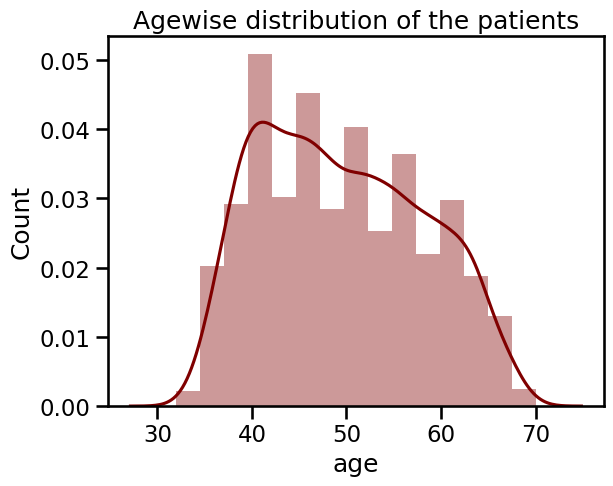

In [211]:
sns.distplot(data_frame['age'], bins=15, kde=True, color='maroon')
plt.ylabel('Count')
plt.title('Agewise distribution of the patients')

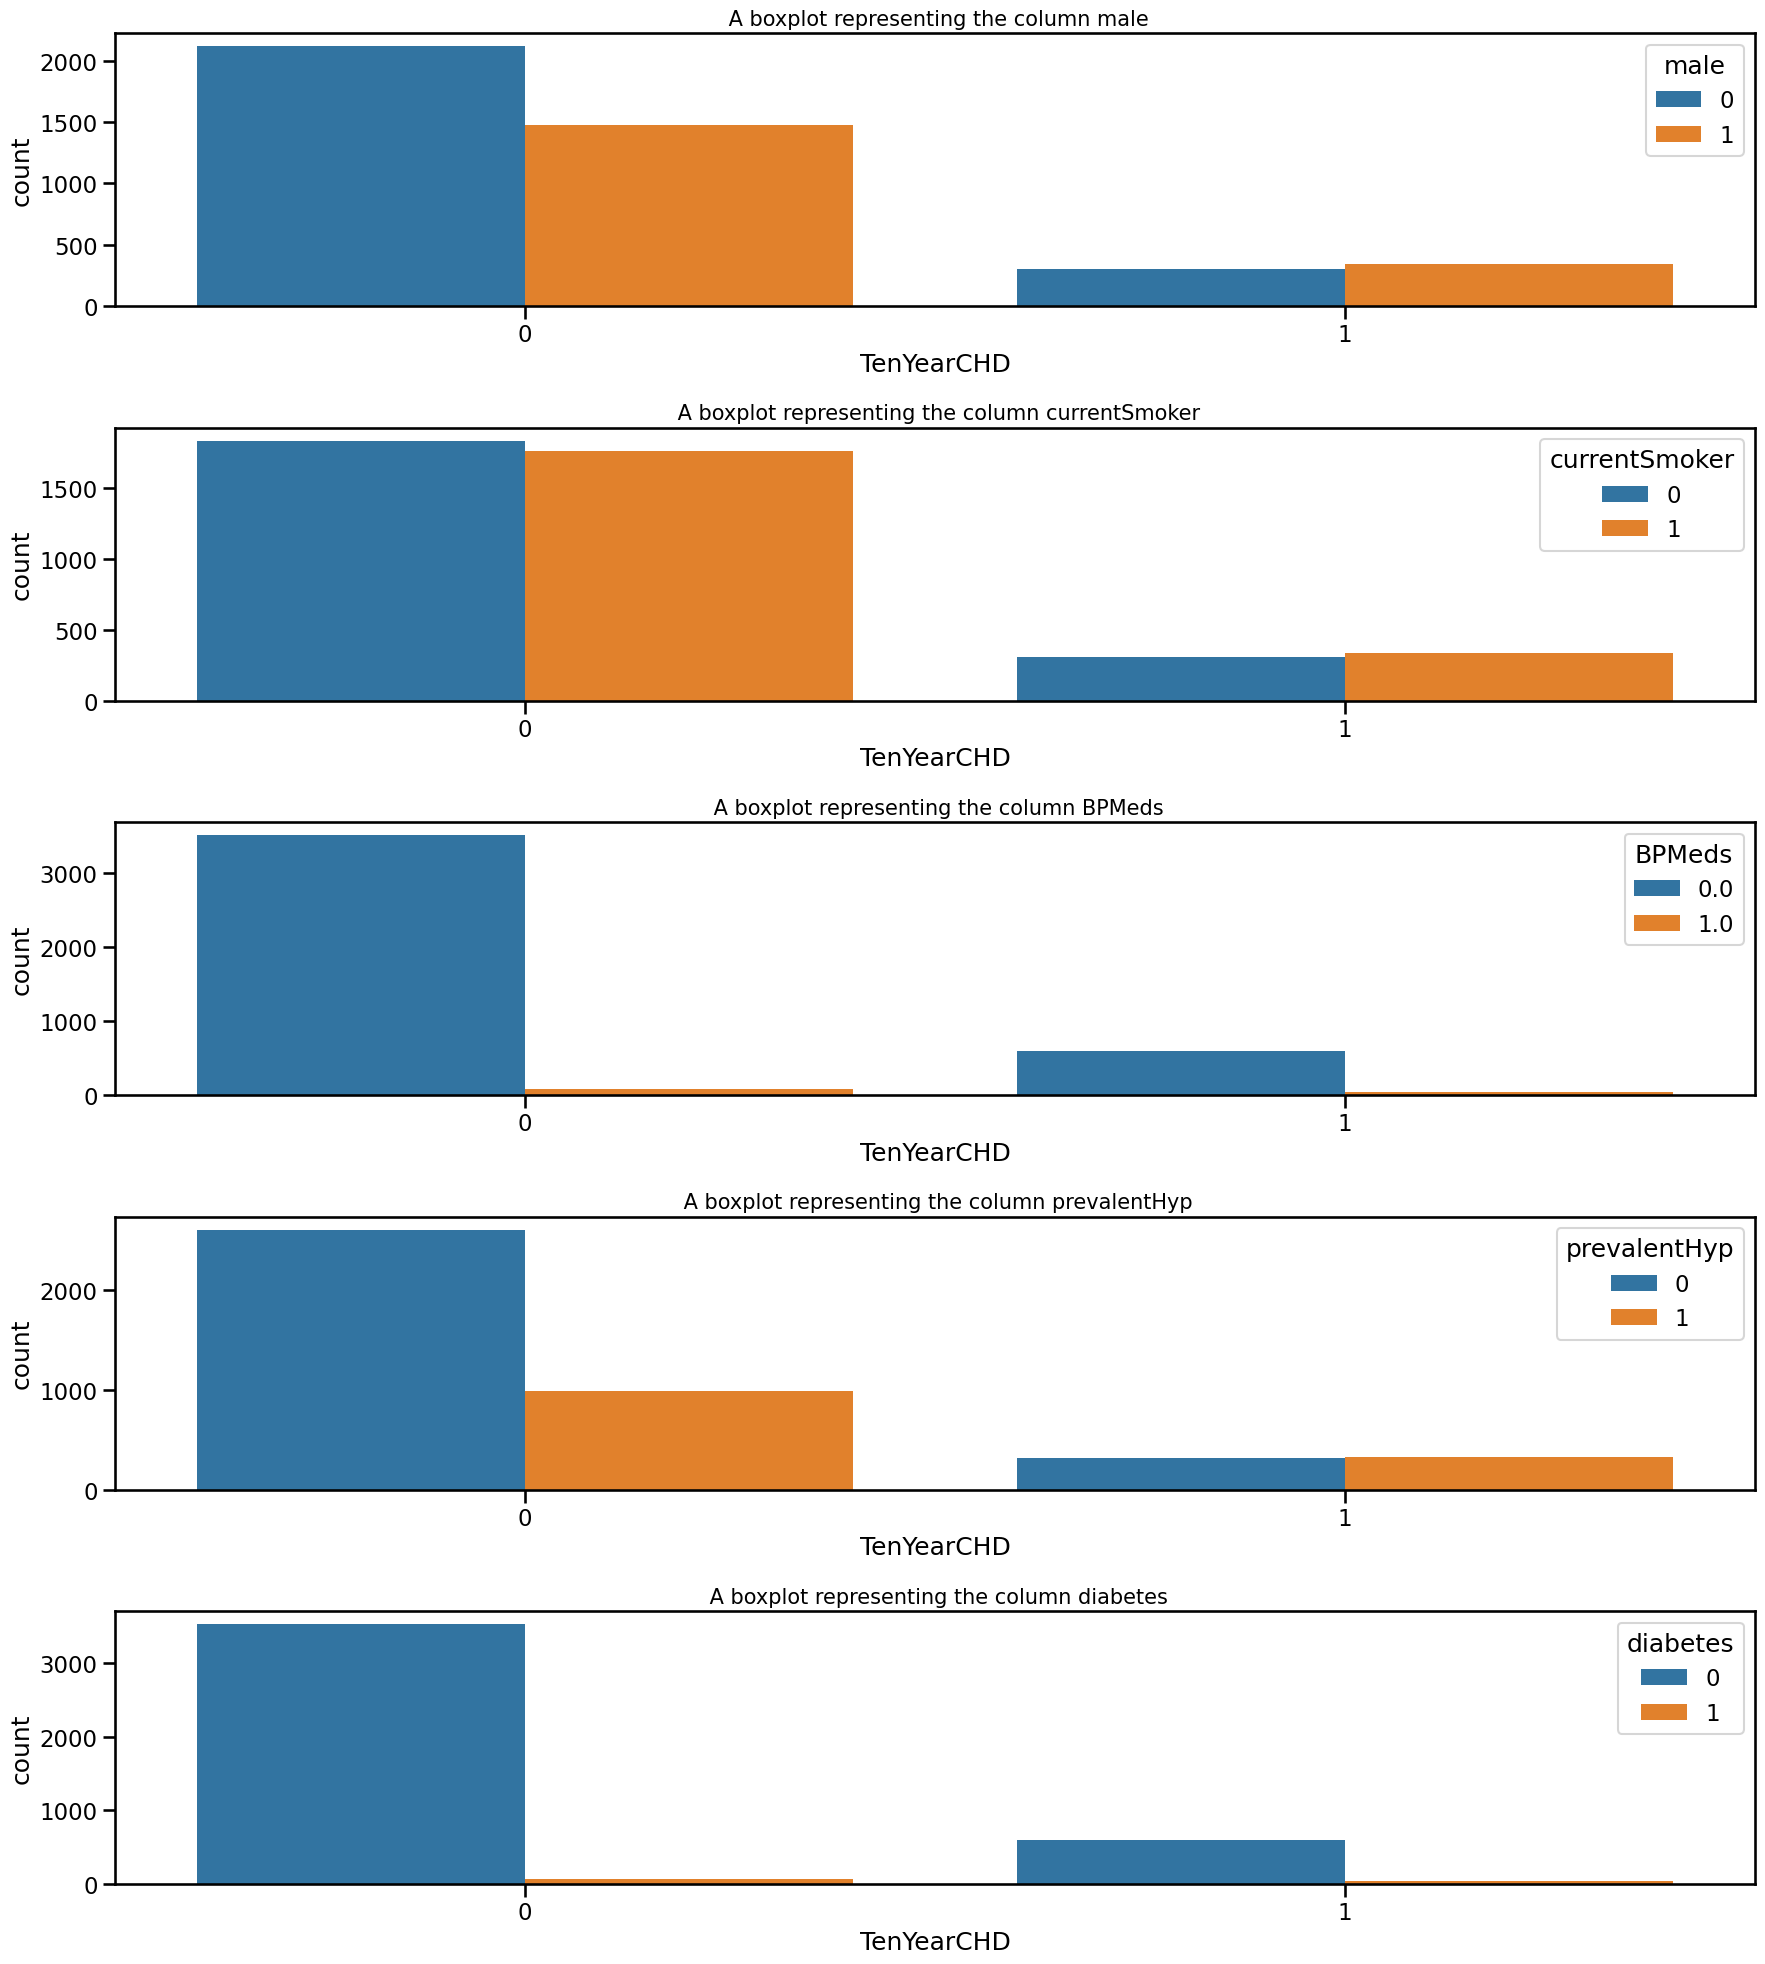

In [212]:
dataset_binary = ['male', 'currentSmoker','BPMeds','prevalentHyp', 'diabetes']

fig, ax = plt.subplots (len(dataset_binary), figsize = (18, 20))
for n,k in enumerate(dataset_binary):
    sns.countplot(x=data_frame['TenYearCHD'], hue = data_frame[k], ax=ax[n])
    ax[n].set_title(" A boxplot representing the column" + " " + k, fontsize = 15)
    fig.tight_layout(pad = 1.1)

## The above plots show that male and Current Smokers are at high risk of getting a heart disease

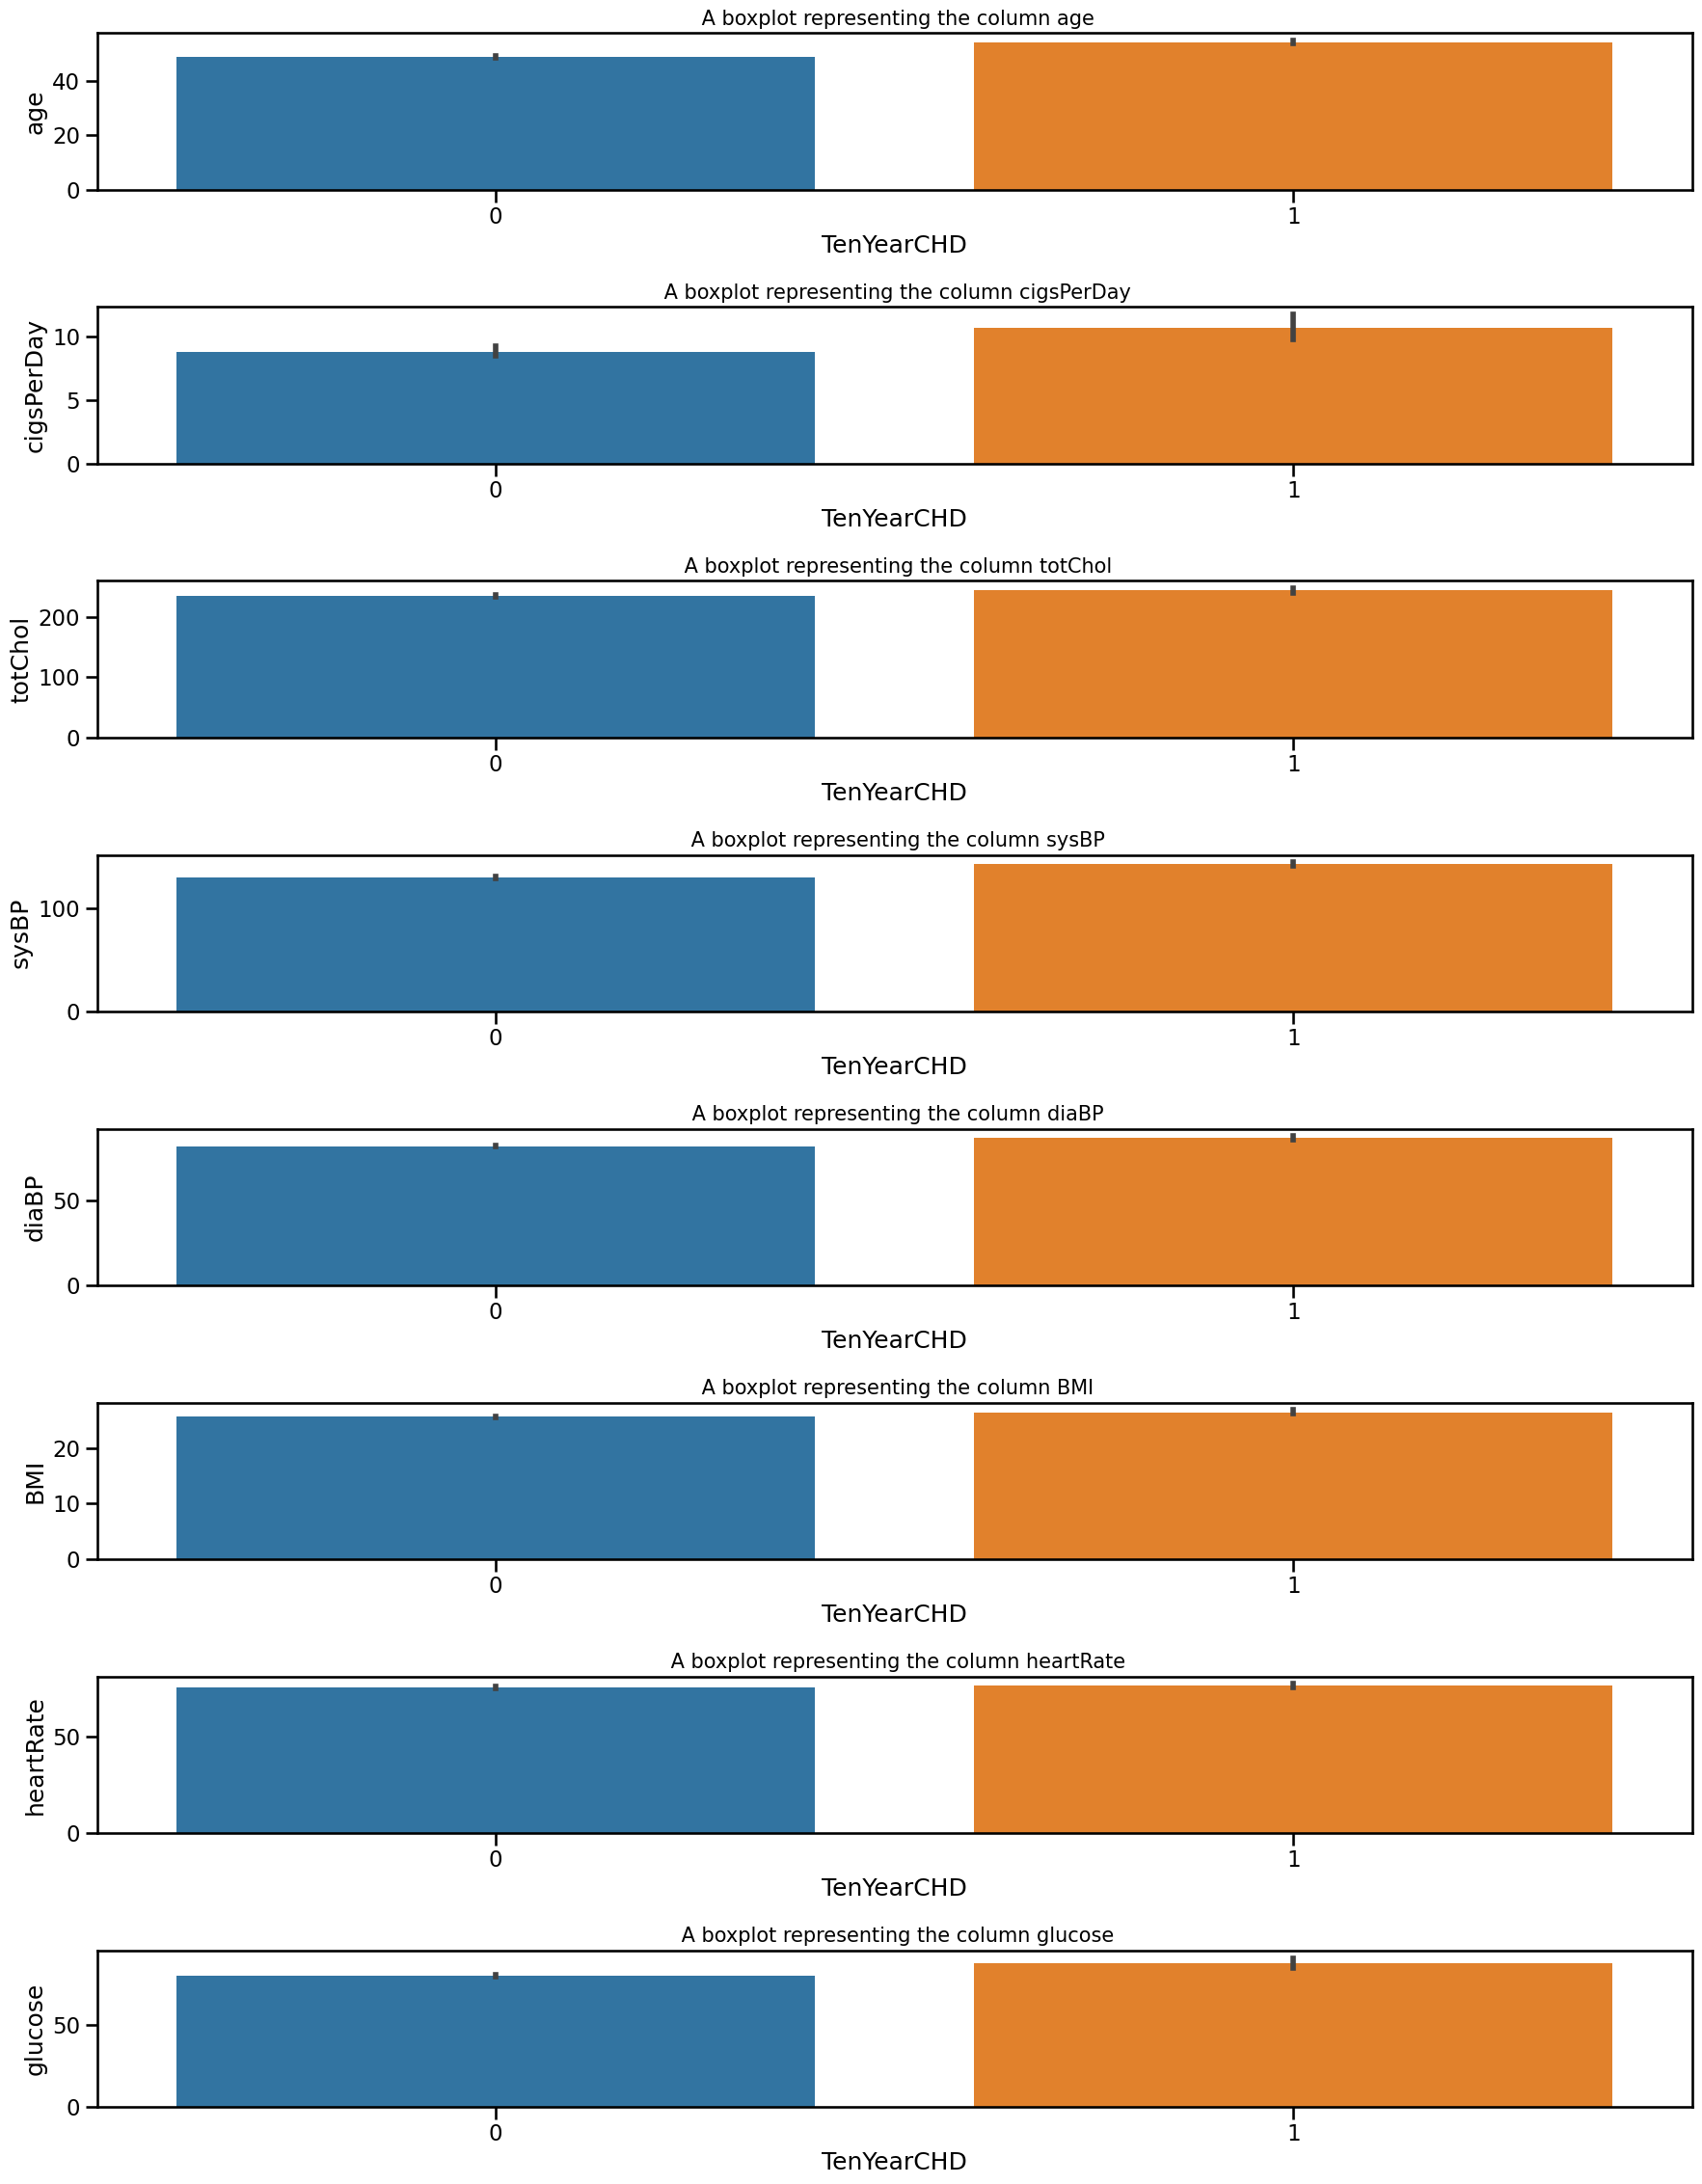

In [213]:
dataset_num = ['age','cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
fig, ax = plt.subplots (len(dataset_num), figsize = (18, 23))
for n,k in enumerate(dataset_num):
    sns.barplot(x=data_frame['TenYearCHD'], y = data_frame[k], ax=ax[n])
    ax[n].set_title(" A boxplot representing the column" + " " + k, fontsize = 15)
    fig.tight_layout(pad = 1.1)

Observation :

Subjects ranging from Age 40 to 50 are in Majority followed by 50 to 70.

In [214]:
#User-defined function

#Age encoding
def encode_age(data):
    if data <= 40:
        return 0
    if data > 40 and data <=55:
        return 1
    else:
        return 2    

#heart rate encoder
def heartrate_enc(data):
    if data <= 60:
        return 0
    if data > 60 and data <=100:
        return 1
    else:
        return 2

#applying functions
data_frame['enc_hr'] = data_frame['heartRate'].apply(heartrate_enc)
data_frame['encode_age'] = data_frame['age'].apply(lambda x : encode_age(x))

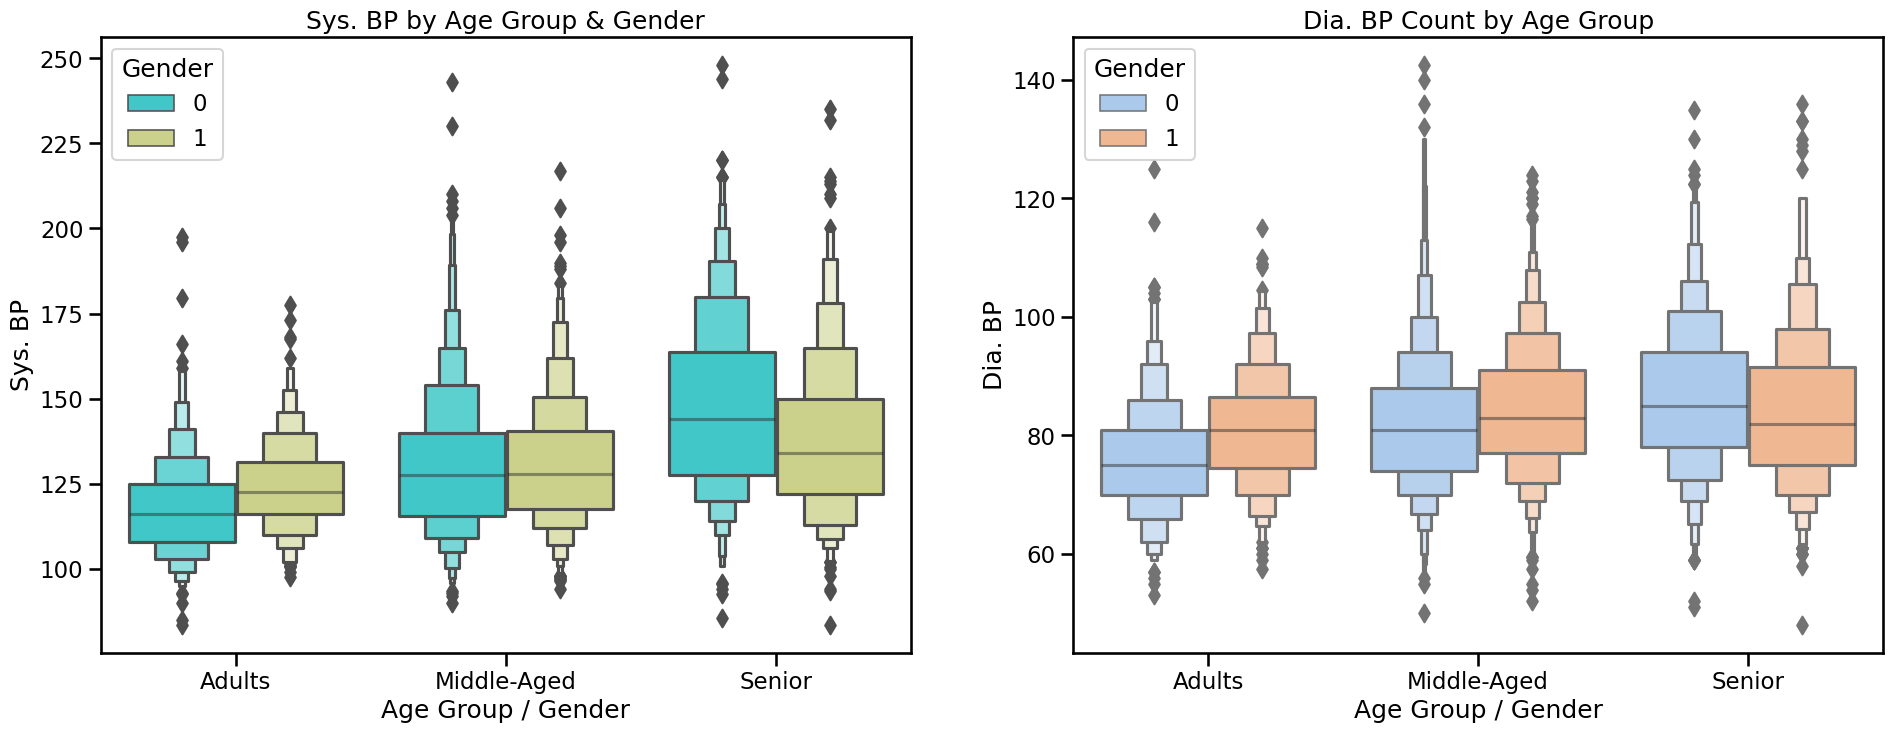

In [215]:
plt.figure(figsize=(23,8))
plt.subplots_adjust(wspace=0.2, hspace=0.3)

plt.subplot(1, 2, 1)
sns.boxenplot(x='encode_age', y='sysBP', hue='male', data=data_frame, palette='rainbow')
plt.xlabel('Age Group / Gender')
plt.ylabel('Sys. BP')
plt.xticks(ticks=[0,1,2], labels=['Adults', 'Middle-Aged', 'Senior'])
plt.title('Sys. BP by Age Group & Gender')
plt.legend(title='Gender')

plt.subplot(1, 2, 2)
sns.boxenplot(x='encode_age', y='diaBP', hue='male', data=data_frame, palette='pastel')
plt.xlabel('Age Group / Gender')
plt.ylabel('Dia. BP')
plt.xticks(ticks=[0,1,2], labels=['Adults', 'Middle-Aged', 'Senior'])
plt.title('Dia. BP Count by Age Group')
plt.legend(title='Gender')

Observations :

1. Sys. BP by Age Group & Gender : Sys. BP is Increasing by Age Group and Gender.
2. Dia. BP by Age Group & Gender : Similar to Sys. BP , the Dia. BP is seen Increasing by Age Group & Gender.

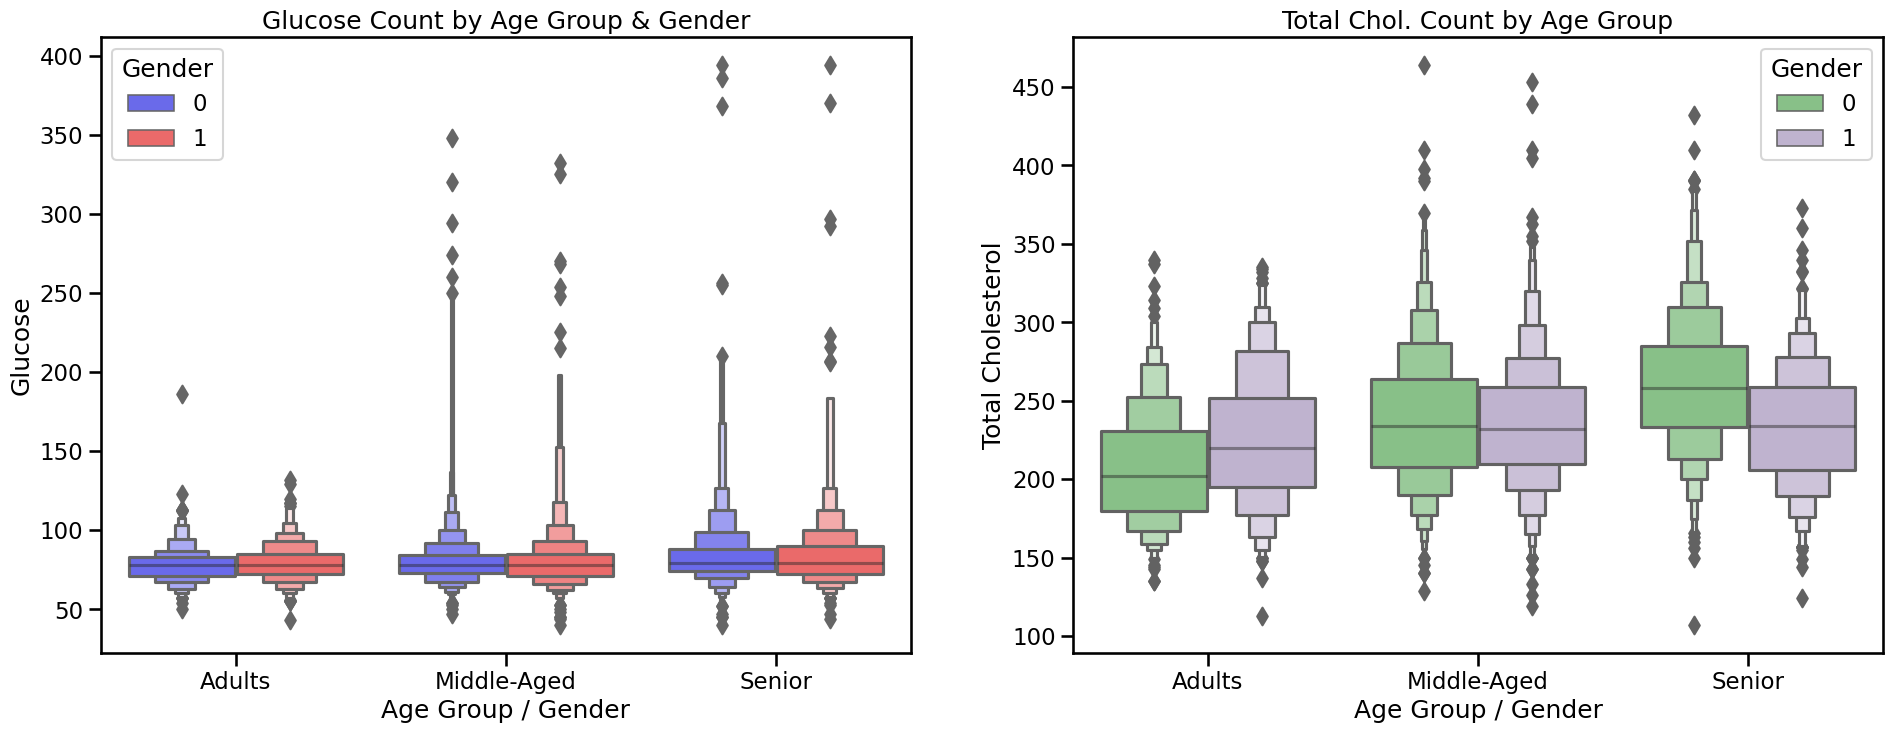

In [216]:
#Multivariate Analysis Pt. 1

plt.figure(figsize=(23,8))
plt.subplots_adjust(wspace=0.2, hspace=0.3)

plt.subplot(1, 2, 1)
sns.boxenplot(x='encode_age', y='glucose', hue='male', data=data_frame, palette='seismic')
plt.xlabel('Age Group / Gender')
plt.ylabel('Glucose')
plt.xticks(ticks=[0,1,2], labels=['Adults', 'Middle-Aged', 'Senior'])
plt.title('Glucose Count by Age Group & Gender')
plt.legend(title='Gender')

plt.subplot(1, 2, 2)
sns.boxenplot(x='encode_age', y='totChol', hue='male', data=data_frame, palette='Accent')
plt.xlabel('Age Group / Gender')
plt.ylabel('Total Cholesterol')
plt.xticks(ticks=[0,1,2], labels=['Adults', 'Middle-Aged', 'Senior'])
plt.title('Total Chol. Count by Age Group')
plt.legend(title='Gender')

Observations :

1. Glucose Count by Age Group & Gender : We can clearly observe that as Age increases the count of Glucose increases too. While Gender wise Glucose Count has almost similiar Median with Few outliers in each.
2. Total Cholesterol by Age Group & Gender : Excluding Outliers, Observation make us Clear that for females Cholesterol level is Increasing by Age considering the Quantile (25%, 50%, 75%) values into account. While, for Males the Cholesterol level Quantile is Approx. Similar for each Age Group.

Text(0.5, 1.0, 'Cigs. per day by Age Group')

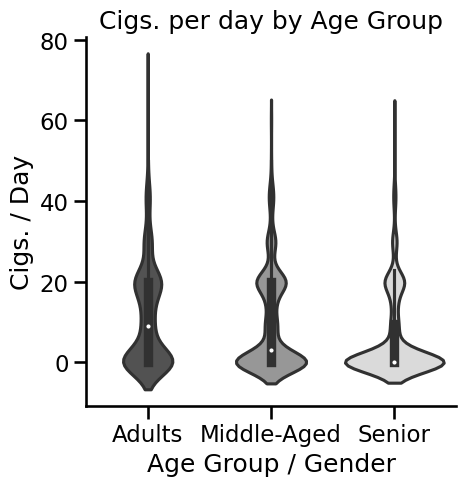

In [217]:
#Violin Plot of Cigsperday by age group

sns.catplot(data=data_frame, x='encode_age', y='cigsPerDay', kind='violin', size=7, palette='Greys_r')
plt.xlabel('Age Group / Gender')
plt.ylabel('Cigs. / Day')
plt.xticks(ticks=[0,1,2], labels=['Adults', 'Middle-Aged', 'Senior'])
plt.title('Cigs. per day by Age Group')

## Observation :

1. Adults : In Adults we can observe that Median values has Lower Kernel Density followed by 75% IQR's Density. While, 25% IQR marks the Higher Kernel Density.
2. Middle-Aged : In Middle-Aged Group we can observe that 25% IQR & Median has Higher Kernel Density while 75% IQR has a quite Lower Kernel Density.
3. Senior : In Seniority section we can observe that Median and 25% IQR are Closely Intact to each other having Higher Kernel Density, while 75% IQR got Lower Kernel Density.

(array([  0.,  20.,  40.,  60.,  80., 100., 120., 140.]),
 [Text(0, 0.0, '0'),
  Text(0, 20.0, '20'),
  Text(0, 40.0, '40'),
  Text(0, 60.0, '60'),
  Text(0, 80.0, '80'),
  Text(0, 100.0, '100'),
  Text(0, 120.0, '120'),
  Text(0, 140.0, '140')])

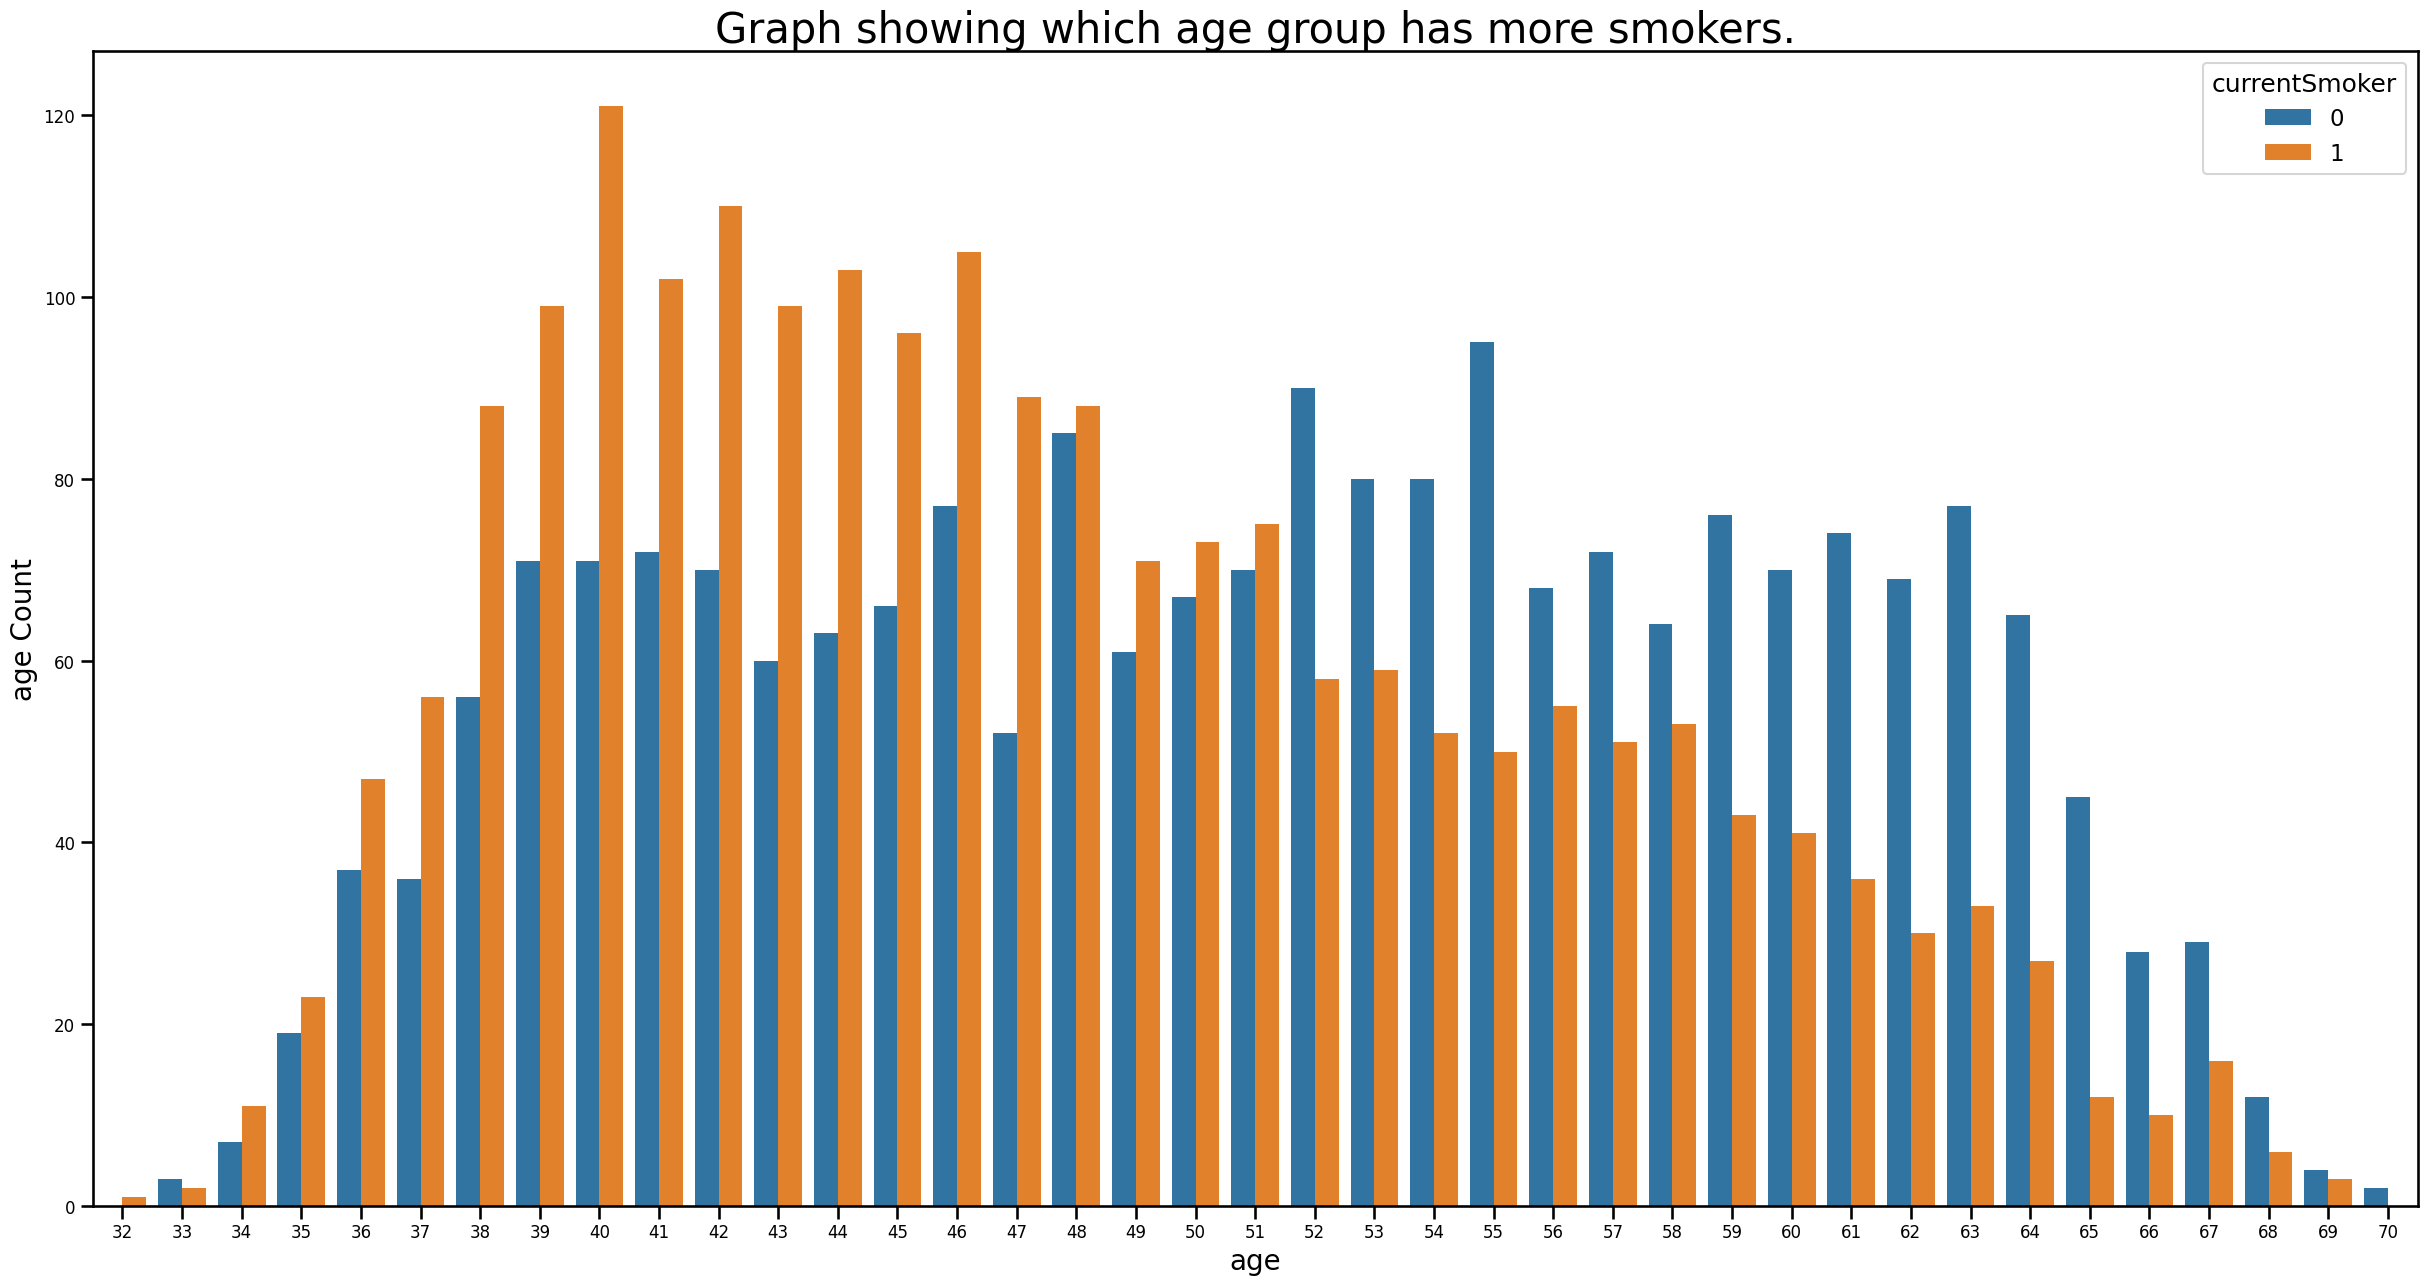

In [218]:
#Distribution of current smokers with respect to age
plt.figure(figsize=(30,15), facecolor='w')
sns.countplot(x="age",data=data_frame,hue="currentSmoker")
plt.title("Graph showing which age group has more smokers.", size=30)
plt.xlabel("age", size=20)
plt.ylabel("age Count", size=20)
plt.xticks(size=12)
plt.yticks(size=12)

## Observation-
Mid-age groups ranging from the age of 38 - 46 have more number of currentSmokers
No currentSmokers observed below the age of 32
maximum age for a currentSmokers is 70

<AxesSubplot: xlabel='TenYearCHD', ylabel='age'>

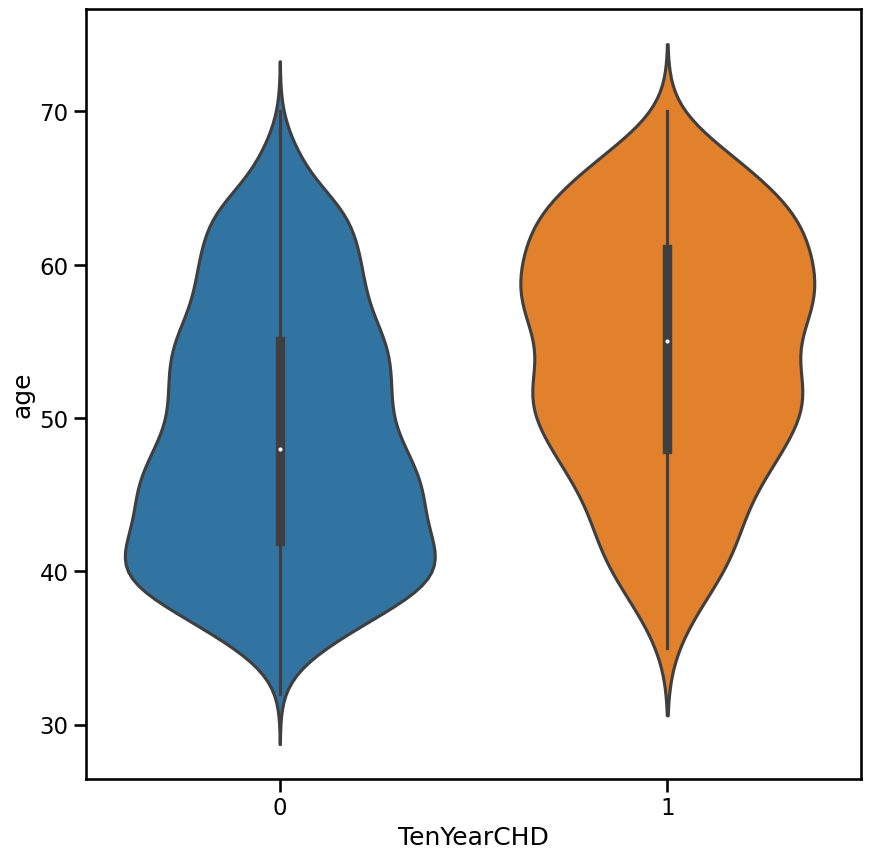

In [219]:
plt.figure(figsize=(10,10))
sns.violinplot(x='TenYearCHD', y='age', data=data_frame)

(array([-50.,   0.,  50., 100., 150., 200., 250., 300.]),
 [Text(0, -50.0, '−50'),
  Text(0, 0.0, '0'),
  Text(0, 50.0, '50'),
  Text(0, 100.0, '100'),
  Text(0, 150.0, '150'),
  Text(0, 200.0, '200'),
  Text(0, 250.0, '250'),
  Text(0, 300.0, '300')])

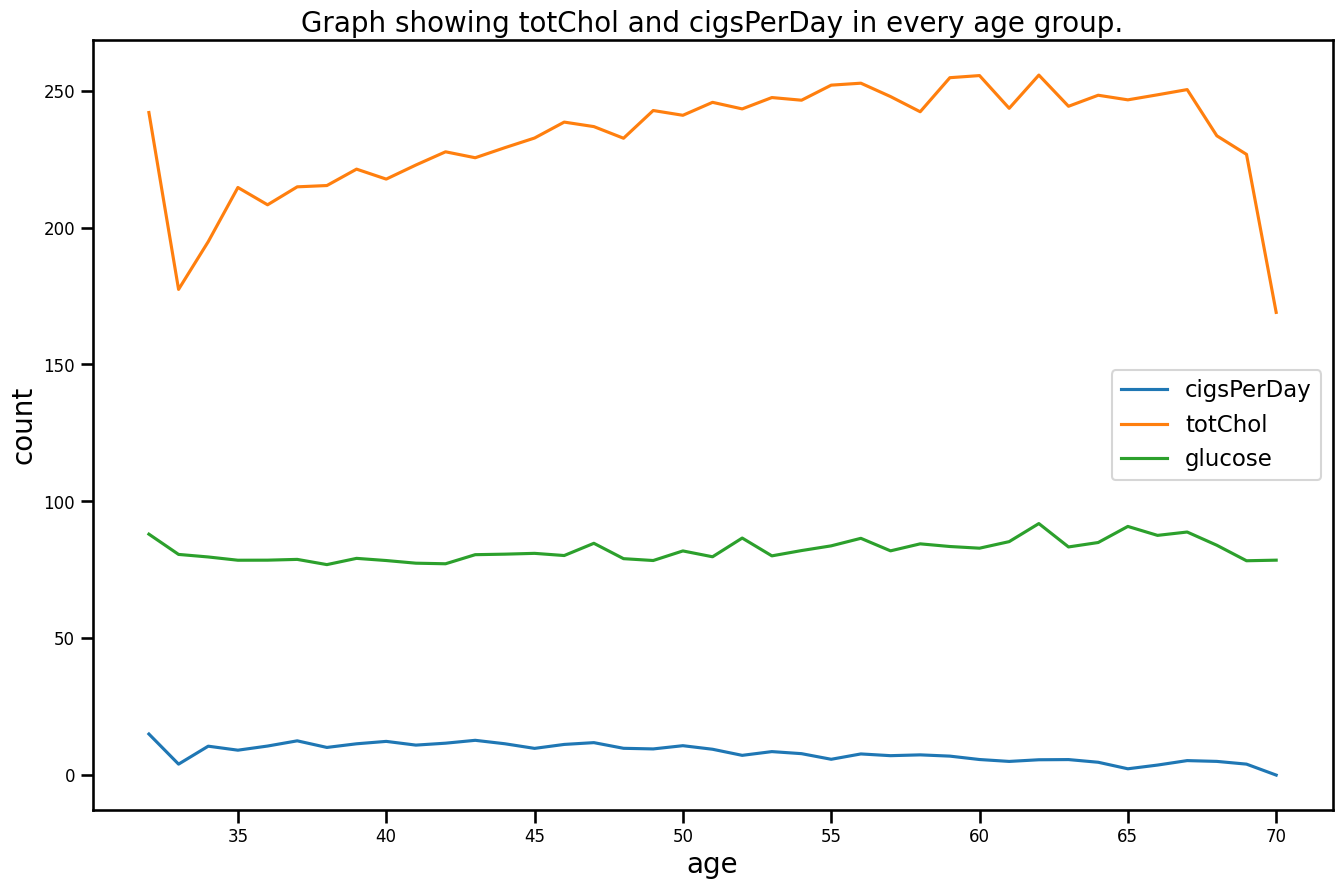

In [220]:
#Plotting a linegraph to check the relationship between age and cigsPerDay, totChol, glucose.

var1 = data_frame.groupby("age").cigsPerDay.mean()
var2 = data_frame.groupby("age").totChol.mean()
var3 = data_frame.groupby("age").glucose.mean()

plt.figure(figsize=(16,10), facecolor='w')
sns.lineplot(data=var1, label="cigsPerDay")
sns.lineplot(data=var2, label="totChol")
sns.lineplot(data=var3, label="glucose")
plt.title("Graph showing totChol and cigsPerDay in every age group.", size=20)
plt.xlabel("age", size=20)
plt.ylabel("count", size=20)
plt.xticks(size=12)
plt.yticks(size=12)

There is a minor relation between totChol and glucose. 
cigsPerDay has a fairly parallel relationship with age.

Text(0.5, 1.0, 'Target Class Count')

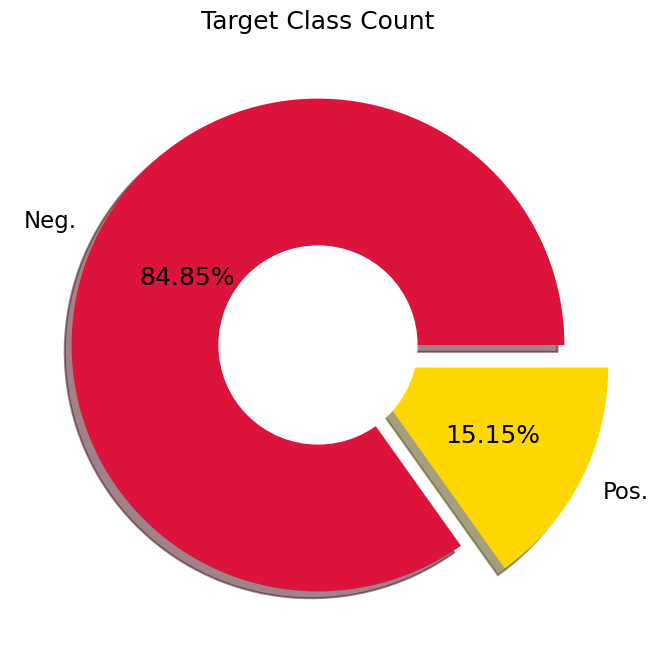

In [221]:
plt.figure(figsize=(8,8))
plt.pie(data_frame['TenYearCHD'].value_counts(), labels=['Neg.','Pos.'], autopct='%1.2f%%', explode=[0,0.2], shadow=True, colors=['crimson','gold'])
my_circle = plt.Circle( (0,0), 0.4, color='white')
p = plt.gcf()
p.gca().add_artist(my_circle)
plt.title('Target Class Count')

In [222]:
data_frame.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD,enc_hr,encode_age
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0,1,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0,1,1
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0,1,1
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1,1,2
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0,1,1


In [223]:
# Dropping columns education
data_frame = data_frame.drop(['education'], axis=1)

##  <a class="anchor" id="sixth-bullet"></a> Version 1
*[Back to Top](#Top)

In [ ]:
# Identify the features with the most importance for the outcome variable Heart Disease

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

# separate independent & dependent variables
X = data_frame.iloc[:,0:14]  #independent columns
y = data_frame.iloc[:,-1]    

# apply SelectKBest class to extract top 10 best features
bestfeatures = SelectKBest(score_func=chi2, k=10)
fit = bestfeatures.fit(X,y)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(X.columns)

#concat two dataframes for better visualization 
featureScores = pd.concat([dfcolumns,dfscores],axis=1)
featureScores.columns = ['Specs','Score']  #naming the dataframe columns
print(featureScores.nlargest(11,'Score'))  #print 10 best features

In [ ]:
featureScores = featureScores.sort_values(by='Score', ascending=False)
featureScores

In [ ]:
# visualizing feature selection
plt.figure(figsize=(20,5))
sns.barplot(x='Specs', y='Score', data=featureScores, palette = "GnBu_d")
plt.box(False)
plt.title('Feature importance', fontsize=16)
plt.xlabel('\n Features', fontsize=14)
plt.ylabel('Importance \n', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [ ]:
# assign the all the column names, exept 'TenYearCHD', to columns 
columns = ['age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'prevalentStroke','BMI', 'glucose']

y = data_frame['TenYearCHD']
X = data_frame[columns]
# train and split the data 
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42, shuffle= False, stratify= None)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
print(len(X_train))
len(X_test)

In [ ]:
clf1 = LogisticRegression(random_state=42)

param_grid = { 
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
}

model_clf1 = GridSearchCV(estimator=clf1, param_grid=param_grid, cv= 10)
model_clf1.fit(X_train, y_train)

In [ ]:
model_clf1.best_params_

In [ ]:
clf1 = LogisticRegression(penalty = 'l1', solver = 'saga')
clf1.fit(X_train, y_train)
predictions1 = clf1.predict(X_test)
print(accuracy_score(y_test, predictions1))
print(cross_val_score(clf1, X_train, y_train, cv = 10, scoring = 'accuracy'))

In [ ]:
cm1 = confusion_matrix(y_test, predictions1) 
conf_matrix1 = pd.DataFrame(data = cm1,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, predictions1))

In [ ]:
# define a new keras model for binary classification
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam, SGD
from keras.layers.core import Dense, Dropout, Activation
def create_binary_model():
    # create model
    model = Sequential()
    model.add(Dense(64, input_dim=11, kernel_initializer='normal', activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(32, kernel_initializer='normal', activation='relu'))
    model.add(Dropout(0.2))
    model.add(Dense(1, activation='sigmoid'))
    
    # Compile model
    opt = SGD(lr=0.01, momentum=0.9)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

binary_model = create_binary_model()

print(binary_model.summary())

In [ ]:
history = binary_model.fit(X_train, y_train, epochs=100, batch_size=150, verbose = 1, validation_data= (X_test,y_test))


In [ ]:
# generate classification report using predictions for binary model 
binary_pred = np.round(binary_model.predict(X_test)).astype(int)

print('Results for Binary Model')
print(accuracy_score(y_test, binary_pred))
print(classification_report(y_test, binary_pred))

In [ ]:
training_loss = history.history['loss']
validation_loss = history.history['val_loss']
no_epochs = 100
epochs_range=range(no_epochs)
plt.plot(epochs_range, training_loss, label='Training Loss')
plt.plot(epochs_range, validation_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss Curve')
plt.xlabel('Epoch Number')
plt.show()

In [ ]:
rf = RandomForestClassifier()
n_estimators = [int(x) for x in np.linspace(start = 200, stop = 2000, num = 100)]
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]
max_depth.append(None)

# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]

# Method of selecting samples for training each tree
bootstrap = [True, False]
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}

rf_random = RandomizedSearchCV(estimator = rf, 
                               param_distributions = random_grid, 
                               n_iter = 100, 
                               cv = 3, 
                               verbose=2, 
                               random_state=7, 
                               n_jobs = -1)

rf_random.fit(X_train,y_train)

In [ ]:
rf_random.best_estimator_

In [ ]:
clf2 = RandomForestClassifier(criterion = 'gini', max_depth = 70, max_features = 'auto', n_estimators = 1781, min_samples_split=10)
clf2.fit(X_train, y_train)
predictions2 = clf2.predict(X_test)
print(accuracy_score(y_test, predictions2))
print(cross_val_score(clf2, X_train, y_train, cv = 10, scoring = 'accuracy'))

In [ ]:
cm2 = confusion_matrix(y_test, predictions2) 
conf_matrix2 = pd.DataFrame(data = cm2,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix2, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, predictions2))

In [ ]:
knn = KNeighborsClassifier(n_neighbors=15)
model3 = knn.fit(X_train, y_train)
prediction3 = knn.predict(X_test)
print(accuracy_score(y_test, predictions3))
print(cross_val_score(model3, X_train, y_train, cv = 10, scoring = 'accuracy'))

In [ ]:
cm3 = confusion_matrix(y_test, predictions3) 
conf_matrix3 = pd.DataFrame(data = cm3,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix3, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, prediction3))

In [ ]:
#Number of trees
n_estimators = [int(i) for i in np.linspace(start=100,stop=1000,num=10)]
max_features = ['auto','sqrt']
max_depth = [int(i) for i in np.linspace(10, 100, num=10)]
max_depth.append(None)
min_samples_split=[2,5,10]
min_samples_leaf = [1,2,4]

#Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

In [ ]:
gb=GradientBoostingClassifier(random_state=0)
#Random search of parameters, using 3 fold cross validation, 
#search across 100 different combinations
gb_random = RandomizedSearchCV(estimator=gb, param_distributions=random_grid,
                              n_iter=100, scoring='f1', 
                              cv=3, verbose=2, random_state=0, n_jobs=-1,
                              return_train_score=True)

# Fit the random search model
gb_random.fit(X_train,y_train)

In [ ]:
gb_random.best_estimator_

In [ ]:
model4 =  GradientBoostingClassifier(max_depth=20, max_features='auto', n_estimators=300,
                           random_state=0)
model4.fit(X_train,y_train)
prediction4 = gvc.predict(X_test)
cm4 = confusion_matrix(y_test, prediction4)
gvc_acc_score = accuracy_score(y_test, prediction4)
print("confussion matrix")
print(cm4)

In [ ]:
cm4 = confusion_matrix(y_test, predictions4) 
conf_matrix4 = pd.DataFrame(data = cm4,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix4, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test,prediction4))

In [ ]:
classifier = SVC(random_state=42)

param_grid = { 
    'kernel': ['poly', 'rbf', 'sigmoid'],
    'degree': [2, 3, 4, 5, 6],
    'gamma' : ['scale', 'auto']
}

gscv_clf5 = GridSearchCV(estimator=classifier, param_grid=param_grid, cv= 10)
gscv_clf5.fit(X_train, y_train)

In [ ]:
gscv_clf5.best_params_

In [ ]:
clf5 = SVC(degree = 2, gamma = 'scale', kernel= 'poly')
clf5.fit(X_train, y_train)
print(cross_val_score(clf5, X_train, y_train, cv = 10, scoring = 'accuracy'))
predictions5 = clf5.predict(X_test)

In [ ]:
cm5 = confusion_matrix(y_test, predictions5) 
conf_matrix5 = pd.DataFrame(data = cm5,  
            columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix5, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, predictions5))

In [ ]:
from sklearn.tree import DecisionTreeClassifier
clf6 = DecisionTreeClassifier(min_samples_split=40, random_state=0) 
clf6.fit(X_train, y_train)
predictions6 = clf6.predict(X_test)

In [ ]:
cm6 = confusion_matrix(y_test, predictions6) 
conf_matrix6 = pd.DataFrame(data = cm6,  
            columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix6, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, predictions6))

In [1]:
lr_false_positive_rate,lr_true_positive_rate,lr_threshold = roc_curve(y_test,predictions1)
knn_false_positive_rate,knn_true_positive_rate,knn_threshold = roc_curve(y_test,predictions3)
rf_false_positive_rate,rf_true_positive_rate,rf_threshold = roc_curve(y_test,predictions2)                                                             
dt_false_positive_rate,dt_true_positive_rate,dt_threshold = roc_curve(y_test,predictions6)
svc_false_positive_rate,svc_true_positive_rate,svc_threshold = roc_curve(y_test,predictions5)
gbc_false_positive_rate,gbc_true_positive_rate,gbc_threshold = roc_curve(y_test,predictions4)

sns.set_style('whitegrid')
plt.figure(figsize=(15,8), facecolor='w')
plt.title('Reciever Operating Characterstic Curve')
plt.plot(lr_false_positive_rate,lr_true_positive_rate,label='Logistic Regression')
plt.plot(rf_false_positive_rate,rf_true_positive_rate,label='Random Forest')
plt.plot(knn_false_positive_rate,knn_true_positive_rate,label='K-Nearest Neighbor')
plt.plot(gbc_false_positive_rate,gbc_true_positive_rate,label='Gradient Boosting Classifier')
plt.plot(svc_false_positive_rate,svc_true_positive_rate, label='Support Vector Classifier')
plt.plot(dt_false_positive_rate,dt_true_positive_rate,label='Decision Tree')

plt.plot([0,1],ls='--')
plt.plot([0,0],[1,0],c='.5')
plt.plot([1,1],c='.5')
plt.ylabel('True positive rate')
plt.xlabel('False positive rate')
plt.legend()
plt.show()

NameError: name 'roc_curve' is not defined

## <a class="anchor" id="seventh-bullet"></a> Version 2
*[Back to Top](#Top)

In [224]:
target1=data_frame[data_frame['TenYearCHD']==1]
target0=data_frame[data_frame['TenYearCHD']==0]

## <a class="anchor" id="eighth-bullet"></a> Resample Data
*[Back to Top](#Top)

In [225]:
from sklearn.utils import resample
target1=resample(target1,replace=True,n_samples=len(target0),random_state=40)
target=pd.concat([target0,target1])
target['TenYearCHD'].value_counts()

0    3595
1    3595
Name: TenYearCHD, dtype: int64

In [226]:
df_data = target

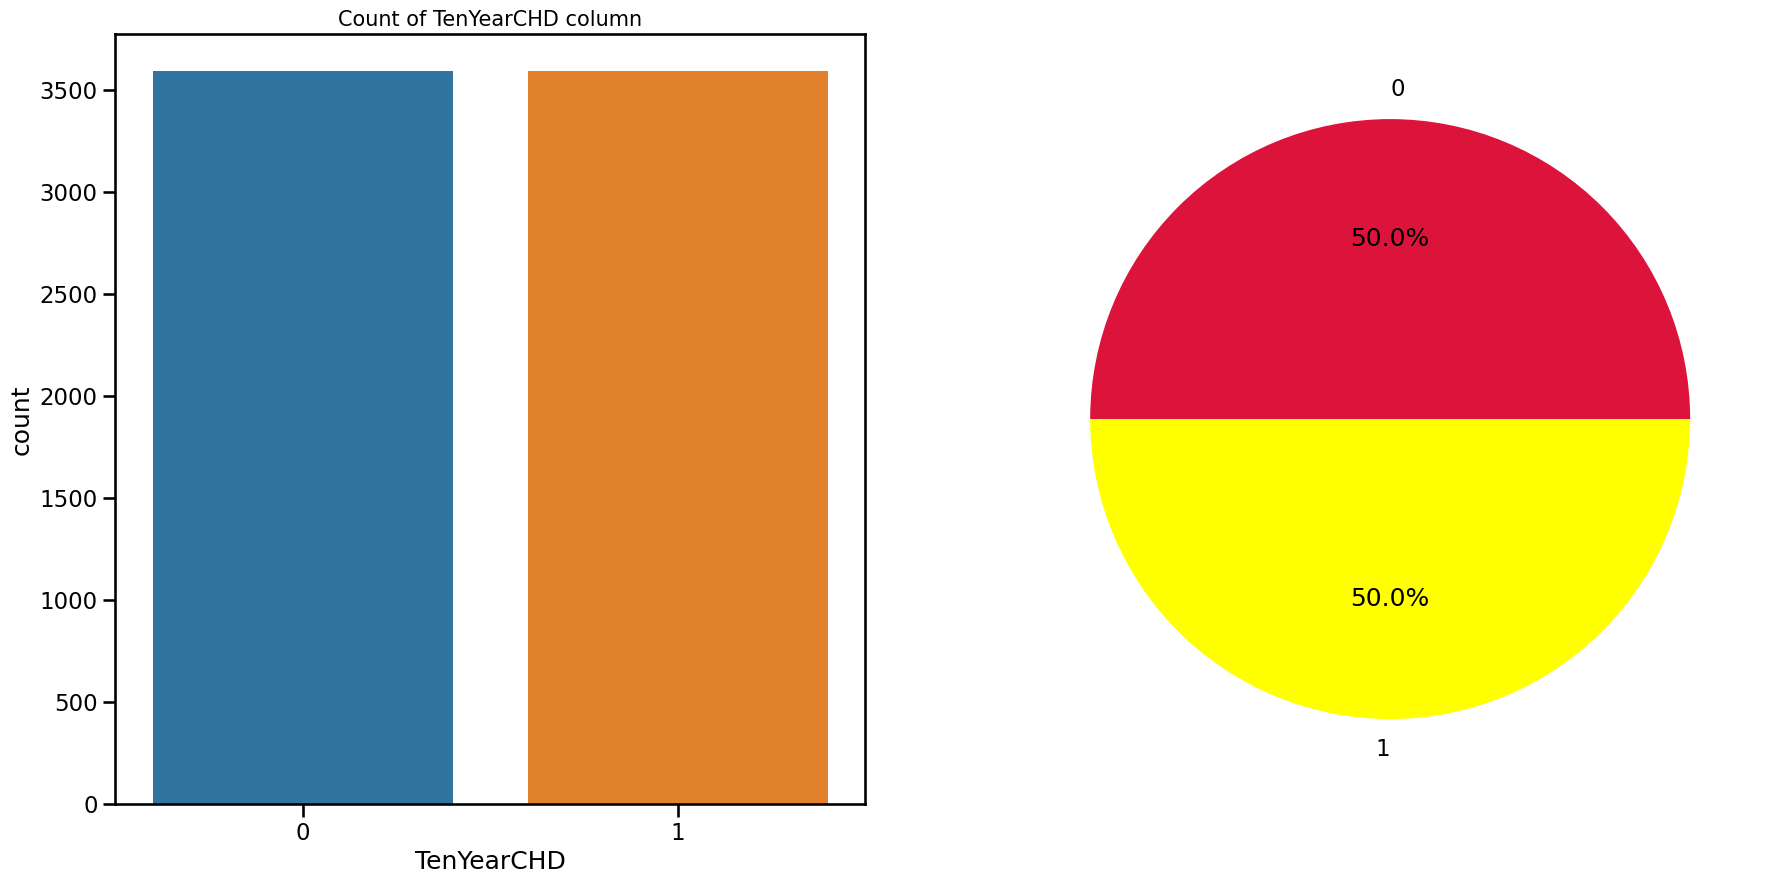

In [227]:
plt.figure(figsize=(12, 10), facecolor='w')
plt.subplots_adjust(right=1.5)
plt.subplot(121)
sns.countplot(x="TenYearCHD", data=df_data)
plt.title("Count of TenYearCHD column", size=15)
plt.subplot(122)
labels=[0,1]
plt.pie(df_data["TenYearCHD"].value_counts(),autopct="%1.1f%%",labels=labels,colors=["crimson","yellow"])
plt.show()

## <a class="anchor" id="ninth-bullet"></a> Feature Selection
*[Back to Top](#Top)

In [228]:
# separate independent & dependent variables
X = df_data.iloc[:,0:14]  #independent columns
y = df_data.iloc[:,-1]    

# apply SelectKBest class to extract top 10 best features
bestfeatures = SelectKBest(score_func=chi2, k=10)
fit = bestfeatures.fit(X,y)
dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(X.columns)

#concat two dataframes for better visualization 
featureScores = pd.concat([dfcolumns,dfscores],axis=1)
featureScores.columns = ['Specs','Score']  #naming the dataframe columns
print(featureScores.nlargest(11,'Score'))  #print 10 best features
print(X.shape)

              Specs        Score
1               age  8570.915050
3        cigsPerDay  3881.387188
9             sysBP  3645.003649
8           totChol  2349.933813
13          glucose   901.802363
10            diaBP   387.371066
6      prevalentHyp   358.977899
2     currentSmoker   154.764025
4            BPMeds   112.701283
7          diabetes    45.003967
5   prevalentStroke    43.559786
(7190, 14)


In [229]:
featureScores = featureScores.sort_values(by='Score', ascending=False)
featureScores

,Specs,Score
1,age,8570.915050
3,cigsPerDay,3881.387188
9,sysBP,3645.003649
8,totChol,2349.933813
13,glucose,901.802363
10,diaBP,387.371066
6,prevalentHyp,358.977899
2,currentSmoker,154.764025
4,BPMeds,112.701283
7,diabetes,45.003967


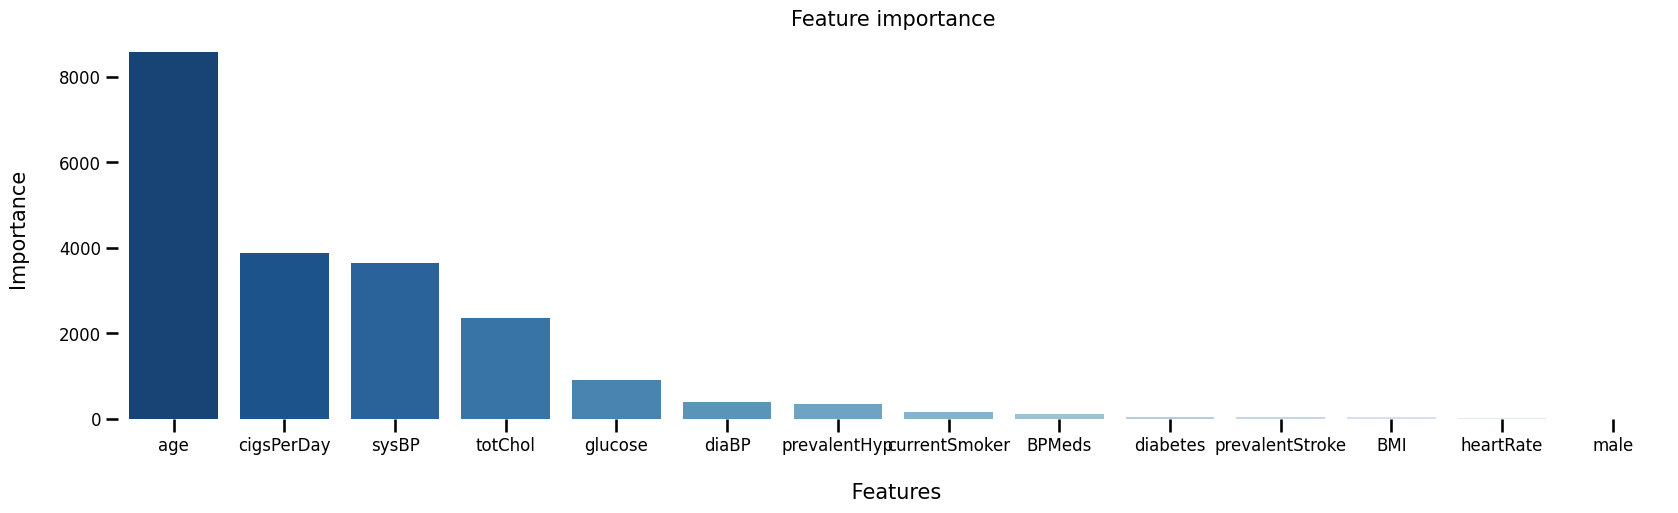

In [230]:
plt.figure(figsize=(20,5))
sns.barplot(x='Specs', y='Score', data=featureScores, palette = "Blues_r")
plt.box(False)
plt.title('Feature importance', fontsize=15)
plt.xlabel('\n Features', fontsize=15)
plt.ylabel('Importance \n', fontsize=15)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

## <a class="anchor" id="tenth-bullet"></a> Test - Train Split
*[Back to Top](#Top)

In [232]:
# assign the all the column names, exept 'TenYearCHD', to columns 
columns = ['age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'prevalentStroke','BMI', 'glucose']

y = df_data['TenYearCHD']
X = df_data[columns]
# train and split the data 
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=1)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
%store X_train
%store X_test

Stored 'X_train' (ndarray)
Stored 'X_test' (ndarray)


## <a class="anchor" id="eleventh-bullet"></a> Logistic Regression
*[Back to Top](#Top)

In [179]:
clf1_1= LogisticRegression(random_state=1)

param_grid = { 
    'penalty': ['l1', 'l2', 'elasticnet', 'none'],
    'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
}

model_clf1_1 = GridSearchCV(estimator=clf1_1, param_grid=param_grid)
model_clf1_1.fit(X_train, y_train)

C:\Users\16674\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py:378: FitFailedWarning: 
45 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\16674\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\16674\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py", line 1091, in fit
    solver = _check_solver(self.solver, self.penalty, self.dual)
  File "C:\Users\16674\AppData\Local\Programs\Pyth

GridSearchCV(estimator=LogisticRegression(random_state=1),
             param_grid={'penalty': ['l1', 'l2', 'elasticnet', 'none'],
                         'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag',
                                    'saga']})

In [180]:
model_clf1_1.best_params_

{'penalty': 'l2', 'solver': 'newton-cg'}

In [181]:
clf1_1 = LogisticRegression(penalty = 'l2', solver = 'newton-cg')
clf1_1.fit(X_train, y_train)
predictions1_1 = clf1_1.predict(X_test)
print(accuracy_score(y_test, predictions1_1))
print(cross_val_score(clf1_1, X_train, y_train,scoring = 'accuracy'))

0.6735261401557285
[0.68396664 0.67562558 0.66419295 0.67625232 0.66512059]


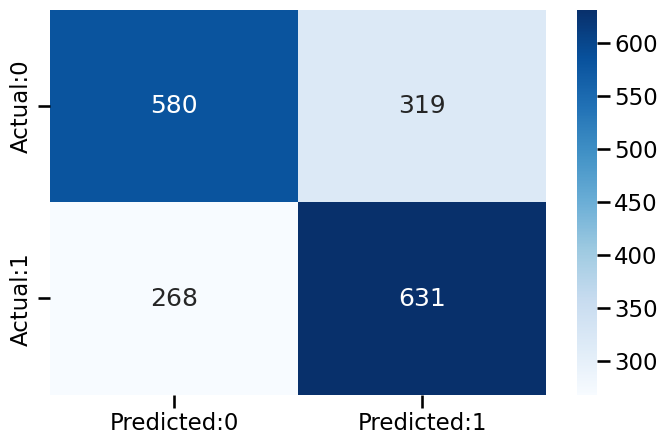

The details for confusion matrix is =


In [182]:
cm1_1 = confusion_matrix(y_test, predictions1_1) 
conf_matrix1_1 = pd.DataFrame(data = cm1_1,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1_1, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [183]:
print(classification_report(y_test, predictions1_1))

              precision    recall  f1-score   support

           0       0.68      0.65      0.66       899
           1       0.66      0.70      0.68       899

    accuracy                           0.67      1798
   macro avg       0.67      0.67      0.67      1798
weighted avg       0.67      0.67      0.67      1798



## <a class="anchor" id="12-bullet"></a> Neural Networks
*[Back to Top](#Top)

In [51]:
# define a new keras model for binary classification
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam, SGD
from keras.layers.core import Dense, Dropout, Activation
def create_binary_model():
    # create model
    model = Sequential()
    model.add(Dense(100, input_dim=12, kernel_initializer='normal', activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(30, kernel_initializer='normal', activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation='sigmoid'))
    
    # Compile model
    opt = SGD(lr=0.01, momentum=0.9)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
    return model

binary_model = create_binary_model()

print(binary_model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 100)               1300      
                                                                 
 dropout (Dropout)           (None, 100)               0         
                                                                 
 dense_1 (Dense)             (None, 30)                3030      
                                                                 
 dropout_1 (Dropout)         (None, 30)                0         
                                                                 
 dense_2 (Dense)             (None, 1)                 31        
                                                                 
Total params: 4,361
Trainable params: 4,361
Non-trainable params: 0
_________________________________________________________________
None


C:\Users\16674\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\optimizers\optimizer_v2\gradient_descent.py:111: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super().__init__(name, **kwargs)


In [52]:
history = binary_model.fit(X_train, y_train, epochs=100, batch_size=150, verbose = 1, validation_data= (X_test,y_test))


Epoch 1/100
36/36 [==============================] - 1s 14ms/step - loss: 0.6933 - accuracy: 0.5108 - val_loss: 0.6922 - val_accuracy: 0.5556
Epoch 2/100
36/36 [==============================] - 0s 3ms/step - loss: 0.6910 - accuracy: 0.5343 - val_loss: 0.6890 - val_accuracy: 0.6240
Epoch 3/100
36/36 [==============================] - 0s 3ms/step - loss: 0.6870 - accuracy: 0.6046 - val_loss: 0.6846 - val_accuracy: 0.6246
Epoch 4/100
36/36 [==============================] - 0s 3ms/step - loss: 0.6829 - accuracy: 0.6167 - val_loss: 0.6795 - val_accuracy: 0.6201
Epoch 5/100
36/36 [==============================] - 0s 3ms/step - loss: 0.6772 - accuracy: 0.6291 - val_loss: 0.6731 - val_accuracy: 0.6201
Epoch 6/100
36/36 [==============================] - 0s 3ms/step - loss: 0.6701 - accuracy: 0.6250 - val_loss: 0.6658 - val_accuracy: 0.6201
Epoch 7/100
36/36 [==============================] - 0s 3ms/step - loss: 0.6620 - accuracy: 0.6320 - val_loss: 0.6582 - val_accuracy: 0.6212
Epoch 8/100


Epoch 59/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6079 - accuracy: 0.6717 - val_loss: 0.6114 - val_accuracy: 0.6719
Epoch 60/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6123 - accuracy: 0.6712 - val_loss: 0.6116 - val_accuracy: 0.6735
Epoch 61/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6112 - accuracy: 0.6727 - val_loss: 0.6124 - val_accuracy: 0.6741
Epoch 62/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6069 - accuracy: 0.6727 - val_loss: 0.6116 - val_accuracy: 0.6741
Epoch 63/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6075 - accuracy: 0.6786 - val_loss: 0.6115 - val_accuracy: 0.6713
Epoch 64/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6103 - accuracy: 0.6725 - val_loss: 0.6118 - val_accuracy: 0.6763
Epoch 65/100
36/36 [==============================] - 0s 6ms/step - loss: 0.6082 - accuracy: 0.6734 - val_loss: 0.6112 - val_accuracy: 0.6724
Epoch 

In [53]:
# generate classification report using predictions for binary model 
binary_pred = np.round(binary_model.predict(X_test)).astype(int)

print('Results for Binary Model')
print(accuracy_score(y_test, binary_pred))
print(classification_report(y_test, binary_pred))

57/57 [==============================] - 0s 893us/step
Results for Binary Model
0.6729699666295884
              precision    recall  f1-score   support

           0       0.70      0.61      0.65       899
           1       0.65      0.74      0.69       899

    accuracy                           0.67      1798
   macro avg       0.68      0.67      0.67      1798
weighted avg       0.68      0.67      0.67      1798



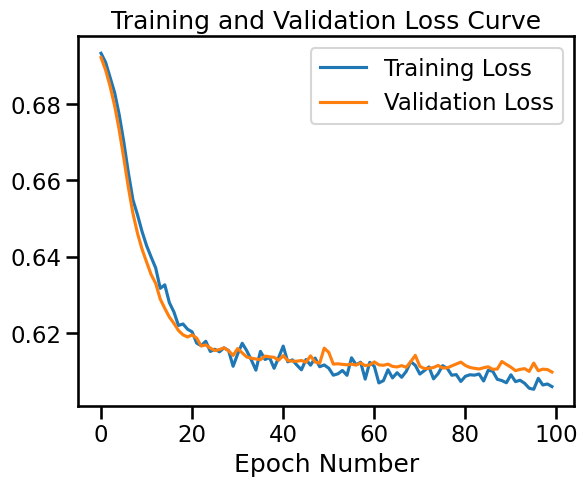

In [54]:
training_loss = history.history['loss']
validation_loss = history.history['val_loss']
no_epochs = 100
epochs_range=range(no_epochs)
plt.plot(epochs_range, training_loss, label='Training Loss')
plt.plot(epochs_range, validation_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss Curve')
plt.xlabel('Epoch Number')
plt.show()

## <a class="anchor" id="13-bullet"></a> Random Forest Classifier
*[Back to Top](#Top)

In [ ]:
rf = RandomForestClassifier()
n_estimators = [int(x) for x in np.linspace(start = 200, stop = 2000, num = 100)]
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]
max_depth.append(None)

# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]

# Method of selecting samples for training each tree
bootstrap = [True, False]
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}

rf_random = RandomizedSearchCV(estimator = rf, 
                               param_distributions = random_grid, 
                               n_iter = 100, 
                               cv = 3, 
                               verbose=2, 
                               random_state=7, 
                               n_jobs = -1)

rf_random.fit(X_train,y_train)

In [ ]:
rf_random.best_estimator_

In [ ]:
clf1_2 = RandomForestClassifier(criterion = 'gini', max_depth = 60, max_features = 'auto', n_estimators = 272)
clf1_2.fit(X_train, y_train)
predictions1_2 = clf1_2.predict(X_test)
print(accuracy_score(y_test, predictions1_2))
print(cross_val_score(clf1_2, X_train, y_train, cv = 3, scoring = 'accuracy'))

In [ ]:
cm1_2 = confusion_matrix(y_test, predictions1_2) 
conf_matrix1_2 = pd.DataFrame(data = cm1_2,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1_2, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, predictions1_2))

## <a class="anchor" id="14-bullet"></a> KNN Classifier
*[Back to Top](#Top)

In [ ]:
param_grid = {'n_neighbors': [1,5,10,25,50,100],
              'weights': ['uniform','distance'],
              'algorithm': ['auto','ball_tree','kd_tree']}


In [ ]:
knn=KNeighborsClassifier()
#Random search of parameters, using 3 fold cross validation, 
#search across 100 different combinations
knn_random = GridSearchCV(knn,param_grid,cv=3,scoring='f1')

# Fit the random search model
knn_random.fit(X_train,y_train)

In [ ]:
knn_random.best_params_

In [ ]:
knn = KNeighborsClassifier(n_neighbors=1, weights='uniform',algorithm='auto')
model1_3 = knn.fit(X_train, y_train)
predictions1_3 = knn.predict(X_test)
print(accuracy_score(y_test, predictions1_3))
print(cross_val_score(model1_3, X_train, y_train, cv = 10, scoring = 'accuracy'))

In [ ]:
cm1_3 = confusion_matrix(y_test, predictions1_3) 
conf_matrix1_3 = pd.DataFrame(data = cm1_3,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1_3, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, predictions1_3))

## <a class="anchor" id="15-bullet"></a> Gradient Boosting Classifier
*[Back to Top](#Top)

In [57]:
#Number of trees
n_estimators = [int(i) for i in np.linspace(start=100,stop=1000,num=10)]
max_features = ['auto','sqrt']
max_depth = [int(i) for i in np.linspace(10, 100, num=10)]
max_depth.append(None)
min_samples_split=[2,5,10]
min_samples_leaf = [1,2,4]

#Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

In [378]:
gb=GradientBoostingClassifier(random_state=0)
#Random search of parameters, using 3 fold cross validation, 
#search across 100 different combinations
gb_random = RandomizedSearchCV(estimator=gb, param_distributions=random_grid,
                              n_iter=100, scoring='f1', 
                              cv=3, verbose=2, random_state=0, n_jobs=-1,
                              return_train_score=True)

# Fit the random search model
gb_random.fit(X_train,y_train)

NameError: name 'random_grid' is not defined

In [379]:
gb_random.best_estimator_

NameError: name 'gb_random' is not defined

In [53]:
import pickle

In [184]:
model1_4 =  GradientBoostingClassifier(max_depth=40, max_features='sqrt', n_estimators=900,min_samples_split=5, random_state=0)
model1_4.fit(X_train,y_train)
prediction1_4 = model1_4.predict(X_test)
cm1_4 = confusion_matrix(y_test, prediction1_4)
gvc_acc_score = accuracy_score(y_test, prediction1_4)
filename = 'finalized_model.sav'
pickle.dump(model1_4, open(filename, 'wb'))

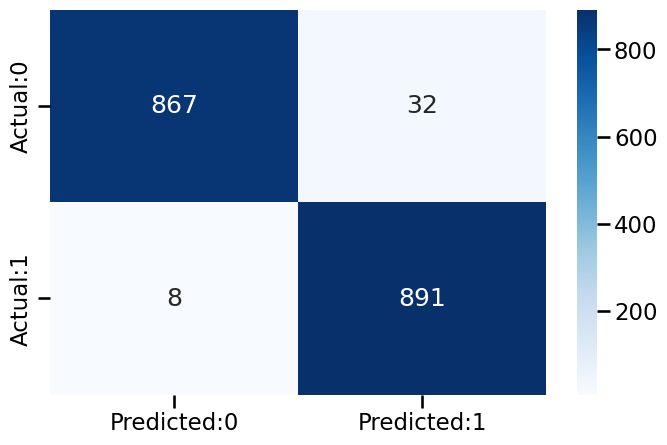

The details for confusion matrix is =


In [185]:
cm1_4 = confusion_matrix(y_test, prediction1_4) 
conf_matrix1_4 = pd.DataFrame(data = cm1_4,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1_4, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [186]:
print(classification_report(y_test, prediction1_4))

              precision    recall  f1-score   support

           0       0.99      0.96      0.98       899
           1       0.97      0.99      0.98       899

    accuracy                           0.98      1798
   macro avg       0.98      0.98      0.98      1798
weighted avg       0.98      0.98      0.98      1798



## <a class="anchor" id="16-bullet"></a> Support Vector Classifier
*[Back to Top](#Top)

In [ ]:
classifier = SVC(random_state=42)

param_grid = { 
    'kernel': ['poly', 'rbf', 'sigmoid'],
    'degree': [2, 3, 4, 5, 6],
    'gamma' : ['scale', 'auto']
}

gscv_clf1_5 = GridSearchCV(estimator=classifier, param_grid=param_grid, cv= 10)
gscv_clf1_5.fit(X_train, y_train)

In [ ]:
gscv_clf1_5.best_params_

In [ ]:
clf1_5 = SVC(degree = 6, gamma = 'scale', kernel= 'poly')
clf1_5.fit(X_train, y_train)
print(cross_val_score(clf1_5, X_train, y_train, cv = 3, scoring = 'accuracy'))
prediction1_5 = clf1_5.predict(X_test)

In [ ]:
cm1_5 = confusion_matrix(y_test, prediction1_5) 
conf_matrix1_5 = pd.DataFrame(data = cm1_5,  
                           columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1_5, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, prediction1_5))

## <a class="anchor" id="17-bullet"></a> Decision Tree Classifier
*[Back to Top](#Top)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
random_grid = {'criterion': ['gini', 'entropy'], 
               'max_depth': [1,5,10,20,50,100], 
               'max_features': [None],
               'min_samples_split': [2,5,10]}

dt=DecisionTreeClassifier(random_state=0)
#Random search of parameters, using 3 fold cross validation, 
#search across 100 different combinations
dt_random = RandomizedSearchCV(estimator=dt, param_distributions=random_grid,
                              n_iter=100, scoring='f1', 
                              cv=3, verbose=2, random_state=0, n_jobs=-1,
                              return_train_score=True)

# Fit the random search model
dt_random.fit(X_train,y_train)

In [ ]:
dt_random.best_estimator_

In [ ]:
clf1_6 = DecisionTreeClassifier(criterion='entropy',max_depth=50, random_state=0) 
clf1_6.fit(X_train, y_train)
prediction1_6 = clf1_6.predict(X_test)

In [ ]:
cm1_6 = confusion_matrix(y_test, prediction1_6) 
conf_matrix1_6 = pd.DataFrame(data = cm1_6,  
            columns = ['Predicted:0', 'Predicted:1'],  
                           index =['Actual:0', 'Actual:1']) 
plt.figure(figsize = (8, 5)) 
sns.heatmap(conf_matrix1_6, annot = True, fmt = 'd', cmap = "Blues") 
plt.show() 
  
print('The details for confusion matrix is =') 

In [ ]:
print(classification_report(y_test, prediction1_6))

## <a class="anchor" id="18-bullet"></a> ROC Curves
*[Back to Top](#Top)

In [ ]:
lr_false_positive_rate,lr_true_positive_rate,lr_threshold = roc_curve(y_test,predictions1_1)
knn_false_positive_rate,knn_true_positive_rate,knn_threshold = roc_curve(y_test,predictions1_3)
rf_false_positive_rate,rf_true_positive_rate,rf_threshold = roc_curve(y_test,predictions1_2)                                                             
dt_false_positive_rate,dt_true_positive_rate,dt_threshold = roc_curve(y_test,prediction1_6)
svc_false_positive_rate,svc_true_positive_rate,svc_threshold = roc_curve(y_test,prediction1_5)
gbc_false_positive_rate,gbc_true_positive_rate,gbc_threshold = roc_curve(y_test,prediction1_4)

sns.set_style('whitegrid')
plt.figure(figsize=(15,8), facecolor='w')
plt.title('Reciever Operating Characterstic Curve')
plt.plot(lr_false_positive_rate,lr_true_positive_rate,label='Logistic Regression')
plt.plot(rf_false_positive_rate,rf_true_positive_rate,label='Random Forest')
plt.plot(knn_false_positive_rate,knn_true_positive_rate,label='K-Nearest Neighbor')
plt.plot(gbc_false_positive_rate,gbc_true_positive_rate,label='Gradient Boosting Classifier')
plt.plot(svc_false_positive_rate,svc_true_positive_rate, label='Support Vector Classifier')
plt.plot(dt_false_positive_rate,dt_true_positive_rate,label='Decision Tree')

plt.plot([0,1],ls='--')
plt.plot([0,0],[1,0],c='.5')
plt.plot([1,1],c='.5')
plt.ylabel('True positive rate')
plt.xlabel('False positive rate')
plt.legend()
plt.show()

## <a class="anchor" id="19-bullet"></a> Feature Importance using LIME
*[Back to Top](#Top)

In [58]:
var_names = ['age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
            'diaBP', 'prevalentStroke','BMI', 'glucose']
var_= {'variable_name':var_names, "coefficient":model1_4.feature_importances_}
var_importance = pd.DataFrame(var_)

In [59]:
model1_4.feature_importances_

array([0.16395573, 0.01457674, 0.05678036, 0.00583345, 0.02903261,
       0.00615932, 0.14576487, 0.16369592, 0.13404985, 0.00248308,
       0.15461255, 0.12305554])

In [60]:
from lime import lime_tabular
from IPython.display import Image as IM
from IPython.display import clear_output
from matplotlib import pyplot as plt
from lime.lime_tabular import LimeTabularExplainer
import random

In [61]:
explainer = LimeTabularExplainer(training_data= X_train, 
                                 mode= "classification", 
                                 feature_names= columns,
                                 verbose=True, 
                                 class_names=['0','1'])

In [62]:
test_sample = X_test[148,:]
exp = explainer.explain_instance(data_row=test_sample,predict_fn= model1_4.predict_proba, num_features=12)
exp

Intercept 0.02079265386043587
Prediction_local [0.17834741]
Right: 0.9999999913147491


In [63]:
 print('R²:' + str(exp.score))

R²:0.09504352768689572


In [64]:
exp.local_exp

{1: [(0, 0.06613980474377018),
  (4, 0.062191396086033),
  (11, 0.04780505898523399),
  (7, 0.047738433642924134),
  (9, -0.03130782935573349),
  (8, -0.020265687465228166),
  (6, -0.009882860943084413),
  (3, 0.008474947936209426),
  (5, -0.008436767605633957),
  (2, -0.005006313590375693),
  (1, 0.0012822417492281692),
  (10, -0.0011776670832697503)]}

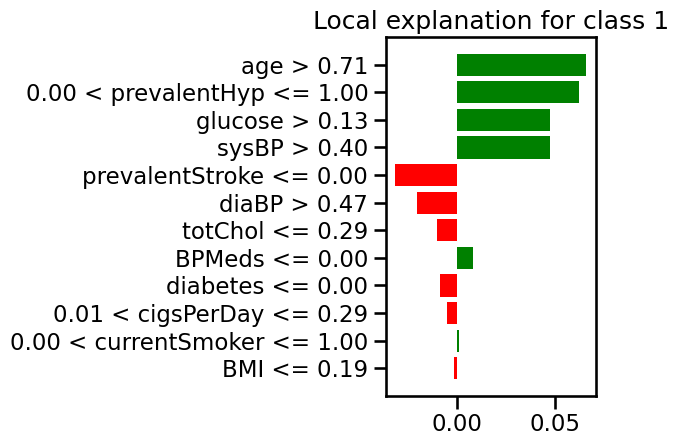

In [65]:
plt = exp.as_pyplot_figure()
plt.tight_layout()

In [66]:
coefs = pd.DataFrame(exp.as_list())[1].sum()
probability = coefs + exp.intercept[1]
print('The probability of class 1 is :', probability )
pd.DataFrame(exp.as_list())

The probability of class 1 is : 0.17834741096050927


,0,1
0,age > 0.71,0.066140
1,0.00 < prevalentHyp <= 1.00,0.062191
2,glucose > 0.13,0.047805
3,sysBP > 0.40,0.047738
4,prevalentStroke <= 0.00,-0.031308
5,diaBP > 0.47,-0.020266
6,totChol <= 0.29,-0.009883
7,BPMeds <= 0.00,0.008475
8,diabetes <= 0.00,-0.008437
9,0.01 < cigsPerDay <= 0.29,-0.005006


In [67]:
exp.show_in_notebook(show_table = True, show_all = False)

In [68]:
print ('Explanation for class %s' % exp.class_names[0])
print ('\n'.join(map(str, exp.as_list())))

Explanation for class 0
('age > 0.71', 0.06613980474377018)
('0.00 < prevalentHyp <= 1.00', 0.062191396086033)
('glucose > 0.13', 0.04780505898523399)
('sysBP > 0.40', 0.047738433642924134)
('prevalentStroke <= 0.00', -0.03130782935573349)
('diaBP > 0.47', -0.020265687465228166)
('totChol <= 0.29', -0.009882860943084413)
('BPMeds <= 0.00', 0.008474947936209426)
('diabetes <= 0.00', -0.008436767605633957)
('0.01 < cigsPerDay <= 0.29', -0.005006313590375693)
('0.00 < currentSmoker <= 1.00', 0.0012822417492281692)
('BMI <= 0.19', -0.0011776670832697503)


In [69]:
d1 = {'age' : 'Age' , 'currentSmoker' : 'Smoking' ,
           'cigsPerDay' : 'High Smoking' , 'BPMeds' : 'BP Medication' ,
           'prevalentHyp' : 'Hypertension', 'diabetes' : 'Diabetes' ,
           'totChol' : 'Cholesterol' , 'sysBP' : 'Systolic Blood Pressure' ,
           'diaBP' : 'Diastolic Blood Pressure' , 'prevalentStroke' : 'Stroke' ,
            'BMI' : 'Body Mass Index' , 'glucose' : 'Glucose'}

In [70]:
if (exp.predict_proba[1] > 0.50):
    high = 0
    col = ''
    for t in exp.as_list():
        if t[1] > high:
            high = t[1]
            ls = t[0].split()
            for i in ls:
                if i[0].isalpha():
                    col = i
                    break   
##    print(col)  
    marker = 1
    print("The algorithm predicts that you may have heart disease because of column :", d1.get(col))
    disease = d1.get(col)
else:
    print("The algorithm predicts that you may not have a heart disease")

The algorithm predicts that you may have heart disease because of column : Age


## <a class="anchor" id="20-bullet"></a> Disease Prevention Using Web Crawling
*[Back to Top](#Top)

In [71]:
disease_mapping = {'Age' : 'https://my.clevelandclinic.org/health/diseases/16891-heart-disease-adult-congenital-heart-disease' ,  
                   'BP Medication' : 'https://my.clevelandclinic.org/health/diseases/4314-hypertension-high-blood-pressure' , 
                   'Hypertension' : 'https://my.clevelandclinic.org/health/diseases/4314-hypertension-high-blood-pressure' , 
                   'Diabetes' : 'https://my.clevelandclinic.org/health/diseases/9812-diabetes-and-stroke' ,
                   'Cholesterol' : 'https://my.clevelandclinic.org/health/diseases/21656-hyperlipidemia' , 
                   'Systolic Blood Pressure' : 'https://my.clevelandclinic.org/health/diseases/4314-hypertension-high-blood-pressure' ,
                   'Diastolic Blood Pressure' : 'https://my.clevelandclinic.org/health/diseases/4314-hypertension-high-blood-pressure' , 
                    'Stroke' : 'https://my.clevelandclinic.org/health/diseases/5601-stroke' ,
                   'Glucose' : 'https://my.clevelandclinic.org/health/diseases/9815-hyperglycemia-high-blood-sugar'}

In [72]:
disease_mapping_1 = {'High Smoking' : 
                     '''1. Get rid of all cigarettes and anything related to smoking, like lighters and ashtrays
                      2. When you get the urge to smoke, take a deep breath. Hold it for ten seconds and release it slowly. Repeat this several times until the urge to smoke is gone. You can also try meditation to reduce baseline stress levels.
                      3. Drink plenty of fluids, but limit caffeinated beverages and beverages containing alcohol
                      4. Don’t forget to exercise, because it has health benefits and help you relax.''' ,
                     'Smoking' :
                    '''1. Get rid of all cigarettes and anything related to smoking, like lighters and ashtrays
                      2. When you get the urge to smoke, take a deep breath. Hold it for ten seconds and release it slowly. Repeat this several times until the urge to smoke is gone. You can also try meditation to reduce baseline stress levels.
                      3. Drink plenty of fluids, but limit caffeinated beverages and beverages containing alcohol
                      4. Don’t forget to exercise, because it has health benefits and help you relax.''',
                     'Body Mass Index' : 
                     '''1 . 150 minutes a week of aerobic exercise can help reduce abdominal fat and overall obesity. That works out to 30 minutes of activity, five days a week. Choosing activities that you enjoy, such as brisk walking, dancing or swimming, can help you stay motivated.
                        2.  Eating fewer calories can help reduce abdominal fat. Changing your diet can also help you lose weight and improve overall obesity.
                        3. his diet includes eating mostly plant-based foods such as root and green vegetables, fresh fruits, legumes, nuts and whole grains, plus moderate servings of dairy, eggs, fish, lean poultry and seafood.'''}

In [73]:
import bs4 as bs
import requests # For Web Scraping
from pprint import pprint 
if (marker == 1):
    if disease in disease_mapping:
        url = disease_mapping.get(disease)
        page = requests.get(url)
        soup = bs.BeautifulSoup(page.text)
        out = ""
        for i, val in enumerate(soup.find('div', class_ = 'js-section js-section--prevention').find_all('li')):
            pprint(f"{i+1}. {val.text}")
            out+=val.text
    elif disease in disease_mapping_1:
        output = disease_mapping_1.get(disease)
        print(output)


'1. Avoid alcohol and recreational drugs.'
'2. Discuss your medications and vaccinations with your provider.'
'3. Quit smoking and using tobacco products.'
('4. You have a genetic condition such as Down syndrome, Noonan syndrome or '
 'Turner syndrome.')
'5. Your mother had Type 1 or Type 2 diabetes while pregnant.'


In [234]:
import re
import pandas as pd
import bs4
import requests
import spacy
from spacy import displacy
nlp = spacy.load('en_core_web_sm')

from spacy.matcher import Matcher 
from spacy.tokens import Span 

import networkx as nx

import matplotlib.pyplot as plt
from tqdm import tqdm

pd.set_option('display.max_colwidth', 200)
%matplotlib inline

In [235]:
doc = nlp(out)

for tok in doc:
    print(tok.text, "...", tok.dep_)

Avoid ... ROOT
alcohol ... dobj
and ... cc
recreational ... amod
drugs ... conj
. ... punct
Discuss ... ROOT
your ... poss
medications ... dobj
and ... cc
vaccinations ... conj
with ... prep
your ... poss
provider ... pobj
. ... punct
Quit ... compound
smoking ... ROOT
and ... cc
using ... conj
tobacco ... compound
products ... dobj
. ... punct
You ... nsubj
have ... ROOT
a ... det
genetic ... amod
condition ... dobj
such ... amod
as ... prep
Down ... compound
syndrome ... pobj
, ... punct
Noonan ... compound
syndrome ... conj
or ... cc
Turner ... compound
syndrome ... conj
. ... punct
Your ... poss
mother ... nsubj
had ... ROOT
Type ... nmod
1 ... nummod
or ... cc
Type ... nmod
2 ... nummod
diabetes ... dobj
while ... mark
pregnant ... advcl
. ... punct


In [237]:
def get_entities(sent):
    ## chunk 1
    ent1 = ""
    ent2 = ""

    prv_tok_dep = ""  # dependency tag of previous token in the sentence
    prv_tok_text = ""  # previous token in the sentence

    prefix = ""
    modifier = ""

    #############################################################

    for tok in nlp(sent):
        ## chunk 2
        # if token is a punctuation mark then move on to the next token
        if tok.dep_ != "punct":
            # check: token is a compound word or not
            if tok.dep_ == "compound":
                prefix = tok.text
                # if the previous word was also a 'compound' then add the current word to it
                if prv_tok_dep == "compound":
                    prefix = prv_tok_text + " " + tok.text
                    
                    
                        # check: token is a modifier or not
            if tok.dep_.endswith("mod") == True:
                modifier = tok.text
                # if the previous word was also a 'compound' then add the current word to it
                if prv_tok_dep == "compound":
                    modifier = prv_tok_text + " " + tok.text
                    
                        ## chunk 3
            if tok.dep_.find("subj") == True:
                ent1 = modifier + " " + prefix + " " + tok.text
                prefix = ""
                modifier = ""
                prv_tok_dep = ""
                prv_tok_text = ""
            
            if tok.dep_.find("obj") == True:
                ent2 = modifier + " " + prefix + " " + tok.text

            ## chunk 5  
            # update variables
            prv_tok_dep = tok.dep_
            prv_tok_text = tok.text
    #############################################################
    return [ent1.strip(), ent2.strip()]

In [238]:
get_entities(out)

['such Turner mother', '2  diabetes']

In [244]:
def get_relation(sent):

    doc = nlp(sent)

    # Matcher class object 
    matcher = Matcher(nlp.vocab)

    #define the pattern 
    pattern = [{'DEP':'ROOT'},
            {'DEP':'prep','OP':"?"},
            {'DEP':'agent','OP':"?"},  
            {'POS':'ADJ','OP':"?"}] 

    matcher.add("matching_1", None, pattern) 

    matches = matcher(doc)
    k = len(matches) - 1

    span = doc[matches[k][1]:matches[k][2]] 

    return(span.text)

In [245]:
get_relation(out)

TypeError: add() takes exactly 2 positional arguments (3 given)